# CPC-GRU con las 10 variables de Bassani et al. (2025): cabezal lineal frente a MLP — 12 Hz

**Proyecto Integrador — Equipo 1**

Bassani, Avizzano y Filippeschi (2025), *Deep Learning Algorithms for Human Activity Recognition in Manual Material Handling Tasks* (Sensors 25(21):6705), trabajan con **el mismo dataset** que este proyecto y reconocen las mismas 7 actividades con sólo **10 señales: 8 de movimiento (MVNX) y 2 de sEMG**. Hasta ahora el proyecto ha usado 30 variables MVNX (notebooks 08–11 y avance 5).

## Preguntas

1. **Variables.** ¿El CPC-GRU funciona igual o mejor con las 10 variables del artículo que con las 30 del proyecto?
2. **Cabezal.** Sobre la representación `c_T` del CPC, ¿un **MLP** clasifica mejor que el clasificador lineal, con el CPC **congelado** y con **ajuste fino**?
3. **Cantidad de sujetos.** ¿Cuánto cambia el desempeño si se entrena con 4, 6, 8 o 10 personas? El artículo entrena con 13 sujetos; aquí hay 10 por ronda. La curva de aprendizaje (sección 9) indica si más sujetos ayudarían. La sección 10 llega a 13 sujetos de entrenamiento, como el artículo.

## Diseño

| Elemento | Decisión | Por qué |
|---|---|---|
| Entrada | **Artículo (10):** 2 sEMG + 8 MVNX (sección 2). **Referencia (30):** el CPC-GRU con las 30 variables MVNX del notebook 10 | La referencia se toma de los resultados guardados del notebook 10 (mismos sujetos evaluados; sección 8.1). Con `"referencia_30"` en `RUN_SETS` se puede correr aquí, en las mismas ventanas |
| Ensayos | Los del 08: cada ensayo bimanual se parte en dos ensayos por brazo | La sEMG del artículo es de un brazo; las variables del brazo se toman del mismo lado. Los autores usaron menos ensayos (sección 2) |
| Balanceo | `BALANCEO = "pesos"` (pesos por clase en la pérdida) o `"submuestreo"` (además, se submuestrea `N` en el entrenamiento) | `"pesos"` es la convención del proyecto; `"submuestreo"` se acerca al artículo |
| Etiqueta | `label_mvnx` del instante final de la ventana | La convención del proyecto desde el avance 4 (`LABEL_SOURCE` permite usar la de la sEMG) |
| Ventanas | 48 pasos (4 s) a 12 Hz | Se mantiene la escala temporal del proyecto en esta primera prueba (el artículo usa 1 s a ~240 Hz) |
| Modelo | CPC con encoder causal y **GRU** de 2 capas (256), horizontes de 1 a 12 pasos (1 s) | El CPC-GRU del notebook 10/11, sin cambios |
| Cabezales | 4 variantes por ronda sobre **un solo** preentrenamiento CPC (sección 6) | La diferencia entre variantes sólo puede venir del cabezal o del ajuste fino |
| Evaluación | LOSO con los sujetos 1–12; el siguiente sujeto de la lista es la validación interna; 13 y 14 reservados | El mismo protocolo de los notebooks anteriores |
| Curva de aprendizaje | Las mismas rondas, con 4, 6 u 8 de los 10 sujetos de entrenamiento | Los sujetos evaluados y la validación interna no cambian, y 13 y 14 siguen sin tocarse |
| LOSO con 14 sujetos (sección 10) | Cada sujeto de 1–14 se evalúa entrenando con los otros 13, como el artículo; después se compara el sujeto 11 con el artículo | **Usa los sujetos 13 y 14**: desde esta sección ya no son una prueba reservada |
| 240 Hz con ventanas de 1 s (sección 11) | El LOSO con 14 sujetos de la sección 10 con la escala temporal del artículo: ventanas de 1 s (240 muestras) y un codificador CPC que reduce a 24 Hz | Es la última diferencia de entrada con el artículo: mismas variables, mismos sujetos y misma frecuencia |

# 1. Configuración

In [1]:
import copy, json, os, time
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales a los notebooks 08–11) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
LABEL_SOURCE = "mvnx"                  # "mvnx" (convención desde el avance 4) o "emg" (la del 08)
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de la sonda que decide la parada temprana de CPC

BALANCEO = os.environ.get("NB12_BALANCEO", "pesos")   # "pesos": entropía cruzada ponderada | "submuestreo": además submuestrea N (sólo entrenamiento)

# ----------------------------- Canales sEMG (sección 2: MMH_Dataset_processing.mlx y 11.mat de los autores) -----------------------------
EMG_CHANNEL = {"biceps": 8, "braquiorradial": 4}   # número de canal (1..8) que usa el artículo para cada músculo

# ----------------------------- CPC-GRU (valores del notebook 10/11) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)

# ----------------------------- Cabezales -----------------------------
LOGREG_C = (0.003, 0.01, 0.03, 0.1, 0.3, 1.0)   # regularización de la regresión logística (como el avance 5)
LOGREG_MAX_ITER = 5000                 # el avance 5 se quedó corto con 2000 iteraciones
MLP_HIDDEN = (256, 128)                # capas ocultas del MLP
# Etapa LP (cabezal sobre el CPC congelado): se prueba cada combinación y se elige con la validación interna
LP_GRID = {"lineal": [{"lr": 1e-3, "dropout": 0.0}, {"lr": 1e-2, "dropout": 0.0}],
           "mlp": [{"lr": lr, "dropout": d} for lr in (1e-3, 3e-3) for d in (0.2, 0.5)]}
LP_EPOCHS, LP_PATIENCE = 60, 8
FT_EPOCHS, FT_PATIENCE = 30, 5         # ajuste fino de toda la red (etapa FT)
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
STEPS_CAP = FT_TRAIN_CAP = None        # límites sólo para la corrida de prueba

# ----------------------------- Curva de aprendizaje (sección 9) -----------------------------
CURVA_SIZES = (4, 6, 8)                # sujetos de entrenamiento; el punto de 10 son las rondas principales
CURVA_SETS = ["articulo_10"]           # conjuntos de variables con curva (agregar "referencia_30" duplica el tiempo)
RUN_SETS = ["articulo_10"]             # rondas principales (sección 6); la referencia de 30 variables viene del notebook 10 (sección 8.1)
# Para corridas desde la terminal: NB12_SETS="articulo_10" y NB12_CURVA="" (sin curva) cambian las dos listas
if "NB12_SETS" in os.environ:
    RUN_SETS = [x for x in os.environ["NB12_SETS"].split(",") if x]
if "NB12_CURVA" in os.environ:
    CURVA_SETS = [x for x in os.environ["NB12_CURVA"].split(",") if x]

# Corrida de prueba rápida (2 rondas, pocas épocas) para revisar que todo funciona: NB12_QUICK=1
QUICK = os.environ.get("NB12_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    FOLDS, CURVA_SIZES = (1, 2), (4,)
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = 2, 1, 1, 5
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, LP_EPOCHS, FT_EPOCHS, LOGREG_C = 2_000, 3_000, 2, 1, (0.1, 1.0)
assert BALANCEO in ("pesos", "submuestreo")

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"     # exportación del 07_Sincronizacion
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb12_gru_variables_articulo_fs{TARGET_FS}"
                                      + ("_submuestreo" if BALANCEO == "submuestreo" else "") + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
for d in (SYNC_DIR / "un_brazo", SYNC_DIR / "bimanual"):
    assert d.exists(), f"Falta la exportación sincronizada: {d.relative_to(REPO_DIR)}"
assert not set(CV_SUBJECTS) & set(TEST_SUBJECTS)

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
LABEL_COLORS = {"N": "#9e9e9e", "LF": "#1f77b4", "K": "#ff7f0e", "PT": "#2ca02c", "LT": "#d62728", "W": "#9467bd", "PF": "#8c564b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | balanceo: {BALANCEO} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | balanceo: pesos | QUICK: False
Resultados en: checkpoints/nb12_gru_variables_articulo_fs12


# 2. Las 10 variables del artículo

Todas las variables de entrada están descritas en un solo lugar del artículo: la **sección 3.1, *Dataset and Networks Input*** (versión abierta en PubMed Central: [PMC12610047](https://pmc.ncbi.nlm.nih.gov/articles/PMC12610047/)). La frase que fija el tamaño de la entrada es:

> *"In this work, we adopted an input composed of 10 signals: eight motions and two sEMG signals."*

El tamaño también aparece en las tablas de hiperparámetros: entrada 10 en las **Tablas 1 y 2** (BiLSTM y Sp-DAE) y 10 × 240 en la **Tabla 3** (RCNN).

El artículo **no nombra las columnas MVNX, los ejes, el lado del cuerpo ni los canales sEMG**. Para no adivinar, se usó el archivo de entrada que publican los autores para el sujeto 11, `11.mat` ([repositorio del código](https://github.com/GiuliaBassani/Deep-Learning-Algorithms-for-Human-Activity-Recognition-in-Manual-Material-Handling-Tasks.), lo carga `BiLSTM_LOSO.m`). Contiene las ventanas de 10 × 240 que entran a sus redes. Cada fila se comparó, en las ventanas originales (sin las copias con ruido del aumento de datos), con las columnas del MVNX crudo a 240 Hz y con la sEMG del mismo sujeto, en 6 ensayos: isocinéticos de los dos brazos, MMH a una mano y bimanuales. La columna **"Coincidencia con 11.mat"** es la correlación entre la fila de los autores y la variable calculada aquí.

| # | Variable (nombre aquí) | Texto del artículo (sección 3.1) | Cómo se calcula aquí | Coincidencia con 11.mat (fila) | Notas |
|---|---|---|---|---|---|
| 1 | `biceps_rms` | *"The Root Mean Square (RMS) sEMG of the biceps brachii…"* | `Norm_RMS_8` | 0.997–0.998 (fila 8) | Un solo canal, no el promedio de 7–8 (que da 0.989). Los canales 7–8 son el bíceps según el *live script* del dataset (ver abajo) |
| 2 | `braquiorradial_rms` | *"…and the brachioradialis muscles complete the input."* | `Norm_RMS_4` | 0.989–0.998 (fila 9) | Un solo canal; supera al promedio de 3–4 y al canal 3 en los 6 ensayos |
| 3 | `pecho_flexion` | *"These include the flexion of the chest, …"* | `jointAngle__jL5S1__c3` | 1.0000 (fila 4) | Es la flexión del tronco: idéntica a `jointAngleErgo` Pelvis–T8. T9T8 es la misma señal salvo la escala (08) |
| 4 | `hombro_flexion` | *"…shoulder, …"* | `jointAngle__j{brazo}Shoulder__c3` | 1.0000 (fila 7) | Secuencia ZXY, la estándar de Xsens (la XZY del 08 da 0.9995) |
| 5 | `codo_flexion` | *"…elbow, …"* | `jointAngle__j{brazo}Elbow__c3` | 1.0000 (fila 5) | Del brazo con sEMG |
| 6 | `rodilla_flexion` | *"…and knee;"* | `jointAngle__jRightKnee__c3` | 1.0000 (fila 6) | **Siempre la rodilla derecha**, también cuando la sEMG es del brazo izquierdo |
| 7 | `mano_posicion_frontal` | *"the hand position and acceleration in the front direction relative to the pelvis;"* | Componente *x* de R<sub>pelvis</sub><sup>T</sup> (p<sub>mano</sub> − p<sub>pelvis</sub>) | 1.0000 (fila 2) | Rotación completa al marco del segmento pelvis (*x* = adelante en Xsens), mano del brazo con sEMG |
| 8 | `mano_aceleracion_frontal` | (misma frase) | Componente *x* de R<sub>pelvis</sub><sup>T</sup> a<sub>mano</sub> | 0.998 dentro de cada ventana (fila 3) | La aceleración **de la mano**, sin restar la de la pelvis. En `11.mat` cada ventana tiene además un desplazamiento constante (entre −4 y +2.5 m/s²) que no se pudo explicar (no es la gravedad); aquí no se agrega |
| 9 | `pelvis_vel_horizontal` | *"the velocity on the transversal plane;"* | √(v<sub>x</sub>² + v<sub>y</sub>²) de la pelvis | 0.999 (fila 1) | El plano transversal es el horizontal |
| 10 | `pelvis_altura` | *"and the position on the global vertical direction of the pelvis."* | `position__Pelvis__z` | 1.0000 (fila 0) | Eje vertical global |

**Unidades.** En `11.mat` los ángulos están en radianes, las posiciones en cm y la sEMG en voltios (RMS sin normalizar); aquí, en grados, metros y %MVC (`Norm_RMS`). No importa para el modelo: cada variable se escala en la sección 3, y dentro de un ensayo la normalización por la MVC es un factor constante.

**Asignación de canales sEMG.** El artículo no la da. Está en el *live script* oficial del dataset, [`MMH_Dataset_processing.mlx`](https://github.com/GiuliaBassani/Manual-Material-Handling-Dataset-for-Biomechanical-and-Ergonomics-Analysis.) (Bassani et al., 2021, *IEEE Sensors Journal*, DOI 10.1109/JSEN.2021.3113123):

> *"Column numbering (1...8) corresponds to the following muscles: Extensor digitorum (1-2), Brachioradialis (3-4), Triceps brachii (5-6), Biceps brachii (7-8)."*

El mismo script grafica *"the channel 8 (Biceps brachii)"*, el canal que `11.mat` confirma. El artículo también dice que la RMS se calcula *"with the envelope over a 250 ms window"*: es la misma ventana de las columnas `Norm_RMS` del dataset.

**Ensayos.** Según `11.mat`, los autores usaron los isocinéticos de los dos brazos, los MMH a una mano **sólo del brazo derecho** y los bimanuales **sólo con el brazo izquierdo**. Aquí se usan todos los ensayos y cada bimanual se parte en dos ensayos por brazo, como en el 08: hay más datos y el mismo criterio para los dos lados.

**Diferencias con el artículo que se mantienen a propósito** en esta primera prueba:

- **Escala temporal:** el artículo usa ventanas de *"1 s length with 1 s stride and no overlap"* (sección 3.1) a ~240 Hz; aquí, 4 s a 12 Hz. A 12 Hz, la aceleración de la mano queda suavizada (la exportación aplica un antialias con corte en 4.8 Hz). La sección 11 repite la evaluación con la escala del artículo.
- **Balanceo:** el artículo submuestrea `N` y aumenta las clases pequeñas con ruido gaussiano (se ve en `11.mat`: copias de ventanas de las clases pequeñas con ruido agregado). Aquí, por defecto, se usan pesos por clase en la pérdida, como en los notebooks anteriores; con `BALANCEO = "submuestreo"` también se submuestrea `N` (sección 5).

## 2.1 Lectura de los datos y cálculo de las variables

Se leen sólo las columnas crudas necesarias para los dos conjuntos de variables (artículo y referencia) y se arman los ensayos por brazo del 08. Las 30 variables de referencia se calculan con la misma función `derive_ref` del 08/09.

In [2]:
SIDE_NAME = {"L": "Left", "R": "Right"}
OTHER = {"L": "R", "R": "L"}

# Columnas MVNX crudas de las 30 variables de referencia (las del 08/09)
RAW_REF = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]
)
# Columnas adicionales que necesitan las variables del artículo
RAW_PAPER = ([f"jointAngle__j{s}Shoulder__c3" for s in ("Left", "Right")] + [f"orientation__Pelvis__{a}" for a in "wxyz"]
             + [f"acceleration__{s}Hand__{a}" for s in ("Left", "Right") for a in "xyz"])
RAW_COLUMNS = list(dict.fromkeys(RAW_REF + RAW_PAPER))
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}


def pelvis_x_axis(col):
    """Eje x (adelante) del segmento pelvis expresado en el marco global: primera columna de la matriz de rotación.
    El cuaternión de Xsens (w, x, y, z) rota del segmento al marco global, así que [R^T v]_x = eje_x · v."""
    w, x, y, z = (col(f"orientation__Pelvis__{a}") for a in "wxyz")
    return 1 - 2 * (y * y + z * z), 2 * (x * y + w * z), 2 * (x * z - w * y)


def derive_paper(raw, emg, side):
    """Las 10 variables del artículo, como en 11.mat (sección 2). `emg`: los 8 canales Norm_RMS del brazo; `side`: ese brazo."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    S = SIDE_NAME[side]
    ex = pelvis_x_axis(col)
    frontal = lambda v: sum(e * c for e, c in zip(ex, v))                    # componente x en el marco de la pelvis
    hand_rel = [col(f"position__{S}Hand__{a}") - col(f"position__Pelvis__{a}") for a in "xyz"]
    hand_acc = [col(f"acceleration__{S}Hand__{a}") for a in "xyz"]
    out = {
        "biceps_rms": emg[:, EMG_CHANNEL["biceps"] - 1].astype(np.float64),
        "braquiorradial_rms": emg[:, EMG_CHANNEL["braquiorradial"] - 1].astype(np.float64),
        "pecho_flexion": col("jointAngle__jL5S1__c3"),
        "hombro_flexion": col(f"jointAngle__j{S}Shoulder__c3"),
        "codo_flexion": col(f"jointAngle__j{S}Elbow__c3"),
        "rodilla_flexion": col("jointAngle__jRightKnee__c3"),             # siempre la derecha, como en 11.mat
        "mano_posicion_frontal": frontal(hand_rel),
        "mano_aceleracion_frontal": frontal(hand_acc),
        "pelvis_vel_horizontal": np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y")),
        "pelvis_altura": col("position__Pelvis__z"),
    }
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


def derive_ref(raw, side):
    """Las 30 variables MVNX de referencia (08/09), con las extremidades ipsi/contra respecto al brazo con sEMG."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    roles = (("ipsi", SIDE_NAME[side]), ("contra", SIDE_NAME[OTHER[side]]))
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for rol, s in roles:
        out[f"{rol}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{rol}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{rol}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{rol}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{rol}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{rol}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for rol, s in roles:
        out[f"{rol}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{rol}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                              col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for rol, s in roles:
        out[f"{rol}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    for rol, s in roles:
        out[f"{rol}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{rol}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


rows, paper_parts, ref_parts, emg_parts, lab_parts, offsets = [], [], [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    base = SYNC_DIR / conjunto
    cols = json.loads((base / "columns.json").read_text())
    pos = {c["name"]: i for i, c in enumerate(cols["mvnx"])}
    emg_names = [c["name"] for c in cols["emg"]]
    with np.load(base / "series.npz") as z:
        mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]]
        data = {k: z[k] for k in z.files if k != "mvnx"}
    tr = pd.read_csv(base / "trials.csv")
    for r in tr.itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        for side in (("L", "R") if conjunto == "bimanual" else (r.side,)):
            if conjunto == "bimanual":
                emg = data["emg"][sl][:, [i for i, n in enumerate(emg_names) if n.startswith(f"{side}_")]]
                lab_emg = data[f"label_emg_{side}"][sl]
            else:
                emg, lab_emg = data["emg"][sl], data["label_emg"][sl]
            assert emg.shape[1] == 8
            paper, PAPER_NAMES = derive_paper(mvnx[sl], emg, side)
            ref, REF_NAMES = derive_ref(mvnx[sl], side)
            rows.append({"trial_idx": len(rows), "file": getattr(r, f"emg_file_{side}"), "mvnx_file": r.mvnx_file,
                         "conjunto": conjunto, "subject": r.subject, "task": r.task, "side": side,
                         "offset": offsets[-1], "n_steps": r.n_steps, "validacion_dudosa": bool(r.validacion_dudosa)})
            paper_parts.append(paper); ref_parts.append(ref); emg_parts.append(emg)
            lab_parts.append(data["label_mvnx"][sl] if LABEL_SOURCE == "mvnx" else lab_emg)
            offsets.append(offsets[-1] + r.n_steps)
    del mvnx, data

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
labels_series = np.concatenate(lab_parts).astype(np.int64)
emg_all = np.concatenate(emg_parts)                      # los 8 canales, sólo para la comprobación de la sección 2.2
INPUT_SETS = {
    "articulo_10": {"nombre": "Artículo (10)", "signals": np.concatenate(paper_parts), "names": PAPER_NAMES, "n_emg": 2},
    "referencia_30": {"nombre": "Referencia (30)", "signals": np.concatenate(ref_parts), "names": REF_NAMES, "n_emg": 0},
}
for spec in INPUT_SETS.values():
    spec["binary"] = [i for i, n in enumerate(spec["names"]) if n.endswith(("_talon", "_punta"))]
    assert not np.isnan(spec["signals"]).any(), f"Hay NaN en {spec['nombre']}"
del paper_parts, ref_parts, emg_parts, lab_parts
assert trials["file"].is_unique

print(f"{len(trials)} ensayos por brazo | {len(labels_series):,} instantes ({len(labels_series) / TARGET_FS / 3600:.1f} h) | "
      f"etiqueta: label_{LABEL_SOURCE}")
for key, spec in INPUT_SETS.items():
    print(f"  {spec['nombre']}: {spec['signals'].shape[1]} canales ({spec['n_emg']} sEMG)")
display(trials.groupby(["conjunto", "task"]).agg(ensayos=("file", "size"), sujetos=("subject", "nunique"),
                                               horas=("n_steps", lambda n: n.sum() / TARGET_FS / 3600)).round(2))

627 ensayos por brazo | 426,026 instantes (9.9 h) | etiqueta: label_mvnx
  Artículo (10): 10 canales (2 sEMG)
  Referencia (30): 30 canales (0 sEMG)


ensayos  sujetos  horas
conjunto task                            
bimanual MMH_Bim      244       14   4.20
un_brazo Isokin       220       14   2.73
         MMH_One      163       14   2.93

## 2.2 Comprobaciones de las variables nuevas

1. **Cuánto importa elegir un canal u otro.** El artículo usa un solo canal por músculo (8 y 4). Si los dos canales de cada músculo están muy correlacionados, usar el otro canal o el promedio cambiaría poco. Como control, la correlación entre músculos distintos (bíceps frente a braquiorradial) debería ser menor. La columna **uso** indica qué canal entra al modelo final y qué filas son sólo informativas.
2. **El eje adelante de la pelvis está bien orientado.** La posición frontal de la mano debe ser casi siempre positiva o cercana a 0 con los dos brazos.

In [3]:
c = np.corrcoef(emg_all[::5].T)
pairs = {"bíceps (7–8)": ((6, 7), "Se usa: canal 8 en la versión final (el 7 es informativo)"),
         "braquiorradial (3–4)": ((2, 3), "Se usa: canal 4 en la versión final (el 3 es informativo)"),
         "control: braquiorradial 3 – bíceps 7": ((2, 6), "Informativo: no entra al modelo")}
display(pd.DataFrame({"correlación": {k: c[i, j] for k, ((i, j), _) in pairs.items()},
                      "uso": {k: uso for k, (_, uso) in pairs.items()}}).round(2))

paper = INPUT_SETS["articulo_10"]["signals"]
j = PAPER_NAMES.index("mano_posicion_frontal")
by_side = pd.DataFrame({side: np.percentile(paper[np.concatenate([np.arange(r.offset, r.offset + r.n_steps)
                                                                  for r in trials[trials["side"] == side].itertuples()]), j],
                                            [5, 50, 95]) for side in ("L", "R")}, index=["p5", "mediana", "p95"])
print("Posición frontal de la mano respecto a la pelvis [m], por brazo:")
display(by_side.round(3))

,correlación,uso
bíceps (7–8),0.93,Se usa: canal 8 en la versión final (el 7 es informativo)
braquiorradial (3–4),0.88,Se usa: canal 4 en la versión final (el 3 es informativo)
control: braquiorradial 3 – bíceps 7,0.66,Informativo: no entra al modelo


Posición frontal de la mano respecto a la pelvis [m], por brazo:


,L,R
p5,-0.036,-0.041
mediana,0.089,0.098
p95,0.409,0.412


## 2.3 Las 10 variables en un ensayo

Un ensayo MMH a una mano del sujeto 1, con la actividad de cada instante como fondo. Sirve para ver que cada variable cambia con la actividad: la altura de la pelvis baja al levantar o dejar en el piso (`LF`, `PF`), la velocidad horizontal sube al caminar (`W`) y la sEMG del bíceps sube mientras se sostiene la carga.

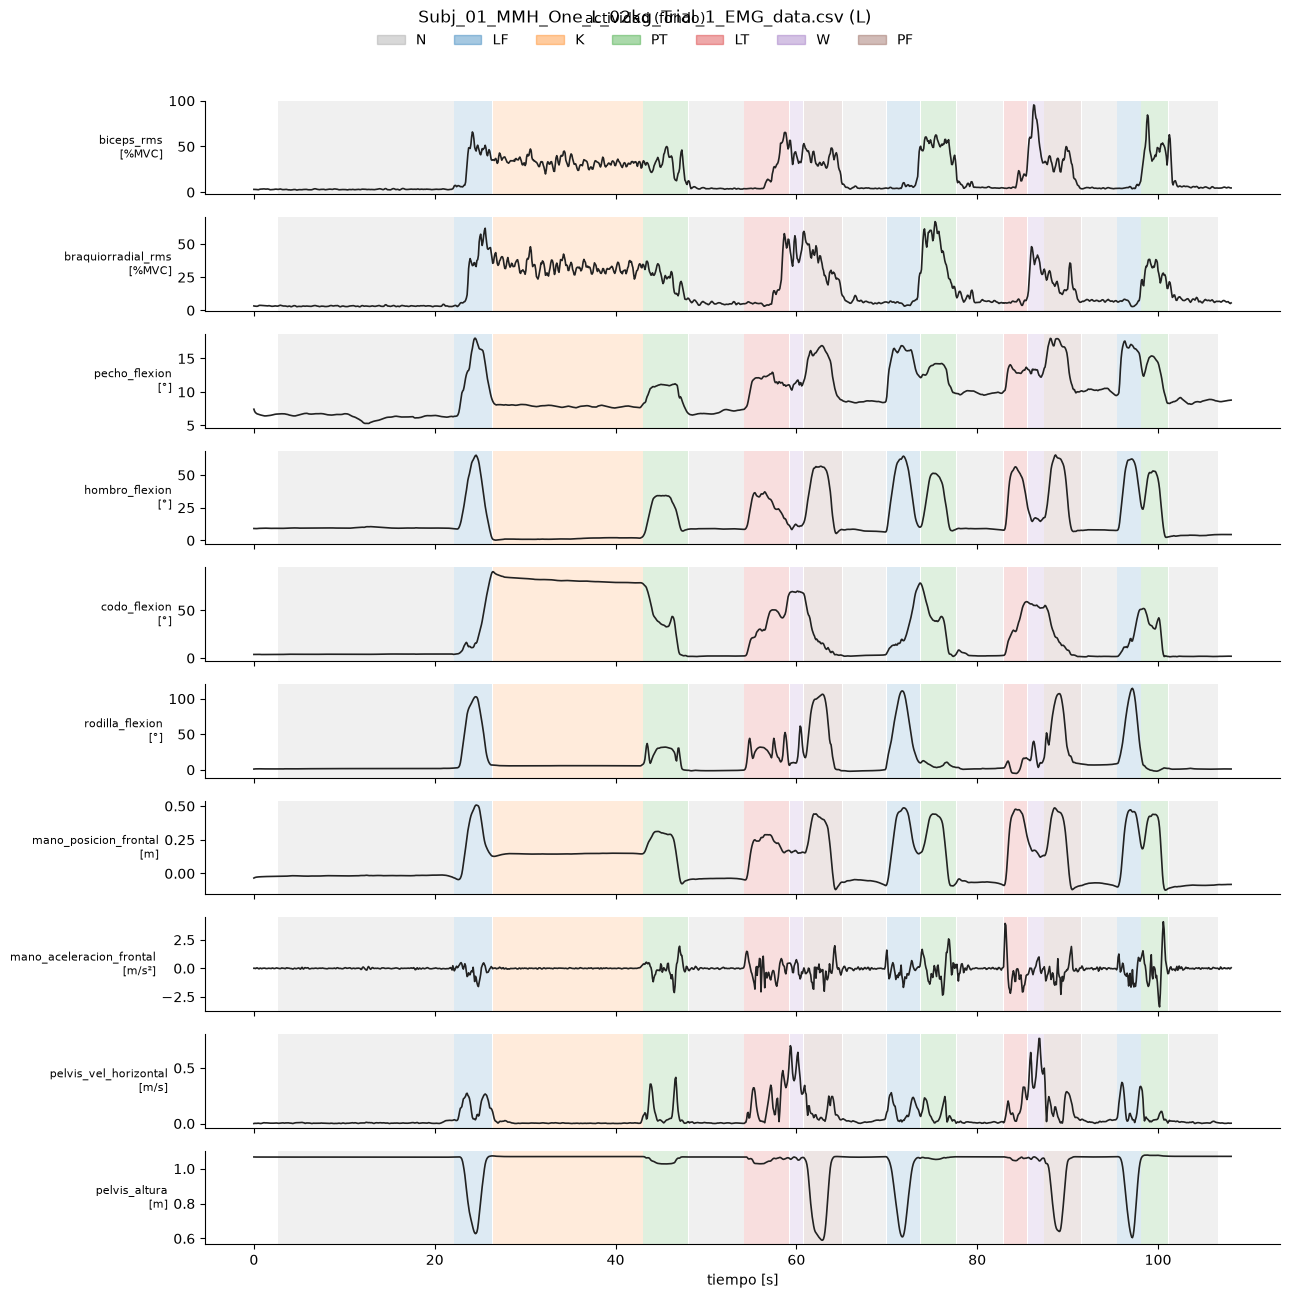

In [4]:
r = trials[(trials["subject"] == 1) & (trials["task"] == "MMH_One")].iloc[0]
sl = slice(r.offset, r.offset + r.n_steps)
t = np.arange(r.n_steps) / TARGET_FS
lab = labels_series[sl]
UNITS = {"biceps_rms": "%MVC", "braquiorradial_rms": "%MVC", "pecho_flexion": "°", "hombro_flexion": "°", "codo_flexion": "°",
         "rodilla_flexion": "°", "mano_posicion_frontal": "m", "mano_aceleracion_frontal": "m/s²",
         "pelvis_vel_horizontal": "m/s", "pelvis_altura": "m"}

fig, axes = plt.subplots(len(PAPER_NAMES), 1, figsize=(13, 13), sharex=True)
for ax, name, values in zip(axes, PAPER_NAMES, INPUT_SETS["articulo_10"]["signals"][sl].T):
    for k, label in enumerate(LABELS):
        ax.fill_between(t, 0, 1, where=lab == k, transform=ax.get_xaxis_transform(), color=LABEL_COLORS[label], alpha=0.15, lw=0)
    ax.plot(t, values, color="#222222", lw=1.2)
    ax.set_ylabel(f"{name}\n[{UNITS[name]}]", rotation=0, ha="right", va="center", fontsize=8)
axes[-1].set_xlabel("tiempo [s]")
handles = [plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[l], alpha=0.4) for l in LABELS]
fig.legend(handles, LABELS, loc="upper center", ncol=len(LABELS), frameon=False, title="actividad (fondo)")
fig.suptitle(f"{r.file} ({r.side})", y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.965))
plt.show()

# 3. Escalado y ventanas

**Escalado** (se reajusta en cada ronda con los sujetos de entrenamiento), el mismo del 08:

- **sEMG:** recorte en los cuantiles 0.1 % y 99.9 %, `log1p` y (x − mediana) / IQR. La envolvente es muy asimétrica y el logaritmo la vuelve casi simétrica.
- **MVNX:** recorte en los cuantiles 0.1 % y 99.9 % y (x − mediana) / (q95 − q5). Los contactos de los pies (0/1, sólo en la referencia) no se modifican.

**Ventanas:** 48 pasos (4 s). Una ventana sin etiqueta para CPC cada 24 pasos y una etiquetada cada 6, con la etiqueta del instante final; se descartan las ventanas cuyo instante final no tiene etiqueta. Las ventanas son **las mismas** para los dos conjuntos de variables.

In [5]:
def fit_scaler(spec, train_subjects, seed=SEED):
    """Parámetros de escalado ajustados con los sujetos de entrenamiento de la ronda."""
    signals, n_emg = spec["signals"], spec["n_emg"]
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    x[:, :n_emg] = np.log1p(x[:, :n_emg])
    q5, q25, center, q75, q95 = np.percentile(x, [5, 25, 50, 75, 95], axis=0)
    scale = np.concatenate([(q75 - q25)[:n_emg], (q95 - q5)[n_emg:]])
    scale = np.where(scale > 0, scale, 1.0)
    b = spec["binary"]
    lower[b], upper[b], center[b], scale[b] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, spec):
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    out = np.clip(spec["signals"], lower, upper)
    out[:, :spec["n_emg"]] = np.log1p(out[:, :spec["n_emg"]])
    return ((out - center) / scale).astype(np.float32)


def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and not cpc_cv["subject"].isin(TEST_SUBJECTS).any()

check = apply_scaler(fit_scaler(INPUT_SETS["articulo_10"], tuple(range(1, 11))), INPUT_SETS["articulo_10"])
print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")
print(f"Artículo (10), escalado con los sujetos 1–10: rango [{check.min():.1f}, {check.max():.1f}]")
del check
display(sup_cv.groupby(["target", "subject"]).size().unstack().rename(index=dict(enumerate(LABELS))))

Ventanas etiquetadas (sujetos 1–12): 51,916 | ventanas sin etiqueta para CPC: 14,500
Artículo (10), escalado con los sujetos 1–10: rango [-1.8, 2.2]


subject,1,2,3,4,5,6,7,8,9,10,11,12
target,,,,,,,,,,,,
N,2263,1488,1791,1693,1615,1626,1808,1785,2202,1579,2572,1623
LF,418,333,376,453,549,357,377,509,379,344,562,359
K,694,217,340,266,333,291,280,323,265,273,956,324
PT,655,497,615,622,669,559,618,781,586,723,743,608
LT,409,433,404,374,459,361,408,420,378,330,395,373
W,192,350,376,347,424,377,268,439,311,358,258,441
PF,346,246,321,256,356,258,298,388,296,319,382,266


# 4. Modelo

## 4.1 CPC-GRU

Las clases del notebook 11 (las mismas del 10), sin cambios:

```
ventana x (canales × 48) → encoder causal (3 Conv1d: 32, 64, 128) → z (48 × 128) → GRU de 2 capas → c (48 × 256) → c_T
                                                                                     └→ W_1…W_12 → InfoNCE (sólo en el preentrenamiento)
```

El preentrenamiento usa negativos **del mismo sujeto** y se detiene con el F1 de una regresión logística sobre `c_T` en el sujeto de validación interna.

## 4.2 Los dos cabezales

**¿Qué cabezal usa el artículo?** El código publicado por los autores ([repositorio](https://github.com/GiuliaBassani/Deep-Learning-Algorithms-for-Human-Activity-Recognition-in-Manual-Material-Handling-Tasks.), `BiLSTM.m` y `RCNN.m`) define, después de la red recurrente, **una sola capa totalmente conectada** y softmax:

```matlab
bilstmLayer(numHiddenUnits,'OutputMode','last')     % RCNN.m: gruLayer(numHiddenUnits,'OutputMode','last')
fullyConnectedLayer(numClasses)
softmaxLayer
classificationLayer
```

Una capa totalmente conectada seguida de softmax es un **clasificador lineal** (una regresión logística multinomial sobre el último estado de la red recurrente). Es lo que el proyecto ha usado hasta ahora.

| Cabezal | Arquitectura | Con CPC congelado | Con ajuste fino |
|---|---|---|---|
| **Lineal** | `Estandarización → Linear(256→7)` | Regresión logística multinomial de scikit-learn sobre `c_T` estandarizado, con `C` elegida en la validación interna (como el avance 5) | La capa de PyTorch **arranca con los pesos de esa regresión logística** y se entrena junto con la red (LP-FT) |
| **MLP** | `Estandarización → Linear(256→256) → ReLU → Dropout → Linear(256→128) → ReLU → Dropout → Linear(128→7)` | Sólo el MLP, sobre `c_T` congelado; la tasa de aprendizaje y el dropout se eligen en la validación interna | El MLP elegido, entrenado junto con la red (LP-FT) |

**Estandarización.** Resta la media y divide entre la desviación estándar de cada una de las 256 dimensiones de `c_T`, calculadas con las ventanas de entrenamiento y fijas después (como el `StandardScaler` de la regresión logística). Una primera versión usaba `LayerNorm` y dropout a la entrada; en una prueba con el sujeto 1, la capa lineal de PyTorch quedaba en F1 0.60 frente a 0.80 de la regresión logística sobre el mismo `c_T`. Con la estandarización y sin dropout subió a 0.73, y el MLP de 0.69 a 0.75. Como la capa lineal entrenada con descenso de gradiente seguía por debajo, el ajuste fino lineal parte directamente de la solución de la regresión logística: así las dos variantes de ajuste fino arrancan del mejor cabezal congelado de su tipo.

**¿Tiene sentido comparar con un MLP?** Sí, pero las dos filas miden cosas distintas:

- **Con el CPC congelado**, el clasificador lineal mide **qué tan buena es la representación** que aprendió CPC sin etiquetas: si las actividades son separables con un hiperplano en `c_T`, la representación ya hizo el trabajo. Si el MLP gana aquí, parte de la mejora viene del clasificador, no de CPC.
- **Con ajuste fino**, toda la red se entrena con etiquetas y el cabezal es sólo la última parte de una red supervisada. Aquí la pregunta es práctica: ¿qué arquitectura generaliza mejor a personas nuevas?
- **Riesgo del MLP:** tiene unos 98 000 parámetros más que el cabezal lineal (≈ 100 000 frente a ≈ 1 800) y sólo hay 10 sujetos de entrenamiento por ronda. Por eso lleva dropout, y su configuración y número de épocas se eligen con el sujeto de validación interna.

In [6]:
@dataclass
class CPCConfig:
    n_channels: int = 10
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class Standardize(nn.Module):
    """(x − media) / desviación por dimensión, con valores fijos (buffers, no se entrenan)."""

    def __init__(self, dim):
        super().__init__()
        self.register_buffer("mean", torch.zeros(dim))
        self.register_buffer("std", torch.ones(dim))

    def fit(self, feats):
        self.mean.copy_(feats.mean(0))
        self.std.copy_(feats.std(0, unbiased=False).clamp_min(1e-6))
        return self

    def forward(self, x):
        return (x - self.mean) / self.std


def make_head(kind, dim, dropout=0.0, n_classes=len(LABELS)):
    """Cabezal sobre c_T: 'lineal' (una capa, como el artículo y el proyecto) o 'mlp' (capas ocultas MLP_HIDDEN)."""
    if kind == "lineal":
        return nn.Sequential(Standardize(dim), nn.Linear(dim, n_classes))
    layers, d = [Standardize(dim)], dim
    for h in MLP_HIDDEN:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    return nn.Sequential(*layers, nn.Linear(d, n_classes))


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + cabezal sobre c_T, el contexto del último instante."""

    def __init__(self, cpc_model, head_kind, dropout=0.0):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        self.head = make_head(head_kind, cpc_model.cfg.c_dim, dropout)

    def features(self, x):
        return self.ar(self.encoder(x).transpose(1, 2))[0][:, -1]

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)


n_par = lambda m: sum(p.numel() for p in m.parameters())
print(f"CPC-GRU con 10 canales: {n_par(build_cpc(10)):,} parámetros (con 30: {n_par(build_cpc(30)):,})")
print(f"Cabezal lineal: {n_par(make_head('lineal', 256)):,} parámetros entrenables | MLP: {n_par(make_head('mlp', 256)):,}")

CPC-GRU con 10 canales: 1,116,320 parámetros (con 30: 1,118,240)
Cabezal lineal: 1,799 parámetros entrenables | MLP: 99,591


# 5. Herramientas de entrenamiento y evaluación

Las funciones del notebook 11, con el cabezal como argumento:

- **`make_sets`:** ventanas de entrenamiento (las de los sujetos de entrenamiento: 10, o menos en la curva de aprendizaje), una muestra de 15 000 para la sonda que decide la parada temprana de CPC, el sujeto de validación interna y el sujeto evaluado.
- **`train_cpc`:** preentrenamiento sin etiquetas con negativos del mismo sujeto.
- **`fit_logreg`:** regresión logística sobre `c_T` congelado; `C` se elige con el F1 en la validación interna.
- **`fit_head`:** entrena sólo el cabezal (lineal o MLP) sobre `c_T` congelado (la etapa LP), con cada configuración de `LP_GRID`; la configuración y las épocas se eligen con la validación interna.
- **`head_from_logreg`:** copia la regresión logística (su estandarización, coeficientes e interceptos) a la capa lineal de PyTorch.
- **`finetune`:** LP-FT, el protocolo de ajuste fino con el que mejor le fue a la GRU en el notebook 10. Parte del cabezal congelado (la regresión logística o el MLP elegido) y después ajusta toda la red, con una tasa de aprendizaje menor en el encoder y la GRU.

Todos usan la entropía cruzada **ponderada por clase** (o `class_weight="balanced"`), por el desbalance de actividades.

**Balanceo.** Con `BALANCEO = "submuestreo"`, antes de los pesos se toma una muestra al azar de las ventanas `N` del entrenamiento, del tamaño de la actividad más frecuente después de `N`. La validación interna y el sujeto evaluado no se tocan: se evalúa siempre con todas sus ventanas.

**Subconjuntos para la curva de aprendizaje.** Con `n_train` sujetos, se ordenan al azar los 10 sujetos de entrenamiento de la ronda (semilla fija por sujeto evaluado) y se toman los primeros `n_train`. Así los subconjuntos están anidados (los 4 están dentro de los 6, y estos dentro de los 8): al pasar de un punto al siguiente sólo se agregan personas. CPC también se preentrena sólo con esos sujetos, porque la pregunta es cuántas personas hay que registrar, con o sin etiquetas.

In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def starts_of(frame):
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def train_subjects_of(held_out, n_train=None):
    """Sujetos de entrenamiento de la ronda; con n_train, los primeros n_train de un orden al azar fijo (anidados)."""
    inner_val = inner_validation_subject(held_out)
    pool = tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))
    if n_train is None or n_train >= len(pool):
        return inner_val, pool
    order = np.random.default_rng(SEED + held_out).permutation(pool)
    return inner_val, tuple(sorted(int(s) for s in order[:n_train]))


def balance(frame, seed=SEED):
    """BALANCEO = 'submuestreo': deja tantas ventanas N como tiene la actividad más frecuente después de N."""
    if BALANCEO != "submuestreo":
        return frame
    n_id = LABELS.index("N")
    counts = frame["target"].value_counts()
    keep = int(counts.drop(n_id, errors="ignore").max())
    is_n = frame["target"] == n_id
    if is_n.sum() <= keep:
        return frame
    return pd.concat([frame[~is_n], frame[is_n].sample(n=keep, random_state=seed)]).sort_index()


def make_sets(held_out, n_train=None):
    inner_val, train_subjects = train_subjects_of(held_out, n_train)
    train = balance(sup_cv[sup_cv["subject"].isin(train_subjects)])
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


# ----------------------------- Serie escalada de la ronda, en el dispositivo -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, canales, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(set_name, held_out, n_train=None):
    global S_T
    spec = INPUT_SETS[set_name]
    inner_val, train_subjects, sets, n_steps = make_sets(held_out, n_train)
    scaler = fit_scaler(spec, train_subjects)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, spec).T)).to(DEVICE)
    return {"set": set_name, "held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects,
            "sets": sets, "n_steps": n_steps, "n_channels": spec["signals"].shape[1], "scaler": scaler}


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


def metrics(y, pred):
    return {"f1_macro": f1_score(y, pred, average="macro"), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred)}


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def cpc_features(model, starts):
    return batched(lambda x: model.encode(x)[1][:, -1], starts)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una regresión logística (C = 1) sobre c_T. Decide la parada temprana de CPC."""
    model.eval()
    rep = lambda part: cpc_features(model, rnd["sets"][part]["starts"]).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(rep("probe_train"), rnd["sets"]["probe_train"]["y"])
    return f1_score(rnd["sets"]["val"]["y"], probe.predict(rep("val")), average="macro")


def train_cpc(rnd, seed=SEED):
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))             # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            f1_val = probe_val_f1(model, rnd)
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    model.eval()
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


# ----------------------------- Cabezales sobre el CPC congelado -----------------------------
def fit_logreg(feats, sets):
    """Regresión logística multinomial sobre c_T estandarizado; C se elige con el F1 en la validación interna."""
    t0, best = time.time(), None
    X_tr, X_val = feats["ft_train"].float().cpu().numpy(), feats["val"].float().cpu().numpy()
    for C in LOGREG_C:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=LOGREG_MAX_ITER, class_weight="balanced"))
        clf.fit(X_tr, sets["ft_train"]["y"])
        f1_val = f1_score(sets["val"]["y"], clf.predict(X_val), average="macro")
        if best is None or f1_val > best["f1_val"] + 1e-4:
            best = {"C": C, "f1_val": f1_val, "model": clf,
                    "converged": bool(clf[-1].n_iter_.max() < LOGREG_MAX_ITER)}
    best["minutes"] = (time.time() - t0) / 60
    return best


def train_head(model, feats, sets, seed, lr):
    """Etapa LP: entrena sólo el cabezal sobre c_T congelado. La época se elige con la validación interna."""
    t0 = time.time()
    model.head[0].fit(feats["ft_train"])                                    # estandarización con las ventanas de entrenamiento
    y_tr = torch.as_tensor(np.array(sets["ft_train"]["y"]), device=DEVICE)
    weights = class_weights(sets["ft_train"]["y"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=lr, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.head.state_dict())}, 0
    for epoch in range(1, LP_EPOCHS + 1):
        model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[s:s + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(feats["ft_train"][idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], model.head(feats["val"]).argmax(1).cpu().numpy(), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best["state"])
    model.head.eval()
    return {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


def fit_head(kind, cpc_model, feats, sets, seed):
    """Etapa LP con cada configuración de LP_GRID[kind]; devuelve el modelo con mejor F1 en la validación interna."""
    best, grid, minutes = None, [], 0.0
    for cfg in LP_GRID[kind]:
        torch.manual_seed(seed)
        model = CPCClassifier(cpc_model, kind, cfg["dropout"]).to(DEVICE)
        info = train_head(model, feats, sets, seed, cfg["lr"])
        grid.append({**cfg, "f1_val": info["f1_val"], "best_epoch": info["best_epoch"]})
        minutes += info["minutes"]
        if best is None or info["f1_val"] > best[1]["f1_val"] + 1e-4:
            best = (model, {**info, **cfg})
    model, info = best
    return model, {**info, "minutes": minutes, "grid": grid}


@torch.no_grad()
def head_from_logreg(model, lr_pipeline):
    """Copia la regresión logística (StandardScaler + LogisticRegression) a la capa lineal: mismas predicciones."""
    scaler, clf = lr_pipeline[0], lr_pipeline[-1]
    std, linear = model.head[0], model.head[-1]
    as_t = lambda a: torch.as_tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)
    std.mean.copy_(as_t(scaler.mean_)); std.std.copy_(as_t(scaler.scale_))
    linear.weight.zero_(); linear.bias.fill_(-30.0)                         # una clase ausente del entrenamiento nunca gana
    rows = torch.as_tensor(clf.classes_, device=DEVICE)
    linear.weight[rows] = as_t(clf.coef_); linear.bias[rows] = as_t(clf.intercept_)
    return model


# ----------------------------- Ajuste fino (LP-FT) -----------------------------
def finetune(model, sets, lp_f1, seed):
    """Etapa FT de LP-FT: parte del cabezal de la etapa LP (época 0) y ajusta toda la red."""
    t0 = time.time()
    best = {"f1": lp_f1, "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}

## 5.1 Una ronda

Cada ronda entrena **un** CPC-GRU y, sobre él, las cuatro variantes:

| Variante | CPC | Cabezal |
|---|---|---|
| `CPC congelado · regresión logística` | congelado | regresión logística (scikit-learn) |
| `CPC congelado · MLP` | congelado | MLP (la etapa LP del ajuste fino con MLP) |
| `Ajuste fino · lineal` | ajustado (LP-FT) | capa lineal |
| `Ajuste fino · MLP` | ajustado (LP-FT) | MLP |

Antes de cada ajuste fino se recargan los pesos del CPC preentrenado, así las dos variantes de ajuste fino parten de la misma red. El ajuste fino lineal arranca con los pesos de la regresión logística, y el MLP, con el MLP congelado elegido.

**Control.** También se guarda la capa lineal de PyTorch entrenada desde cero sobre el CPC congelado (`CPC congelado · lineal (PyTorch)`). Si queda cerca de la regresión logística, la diferencia con el MLP no se debe a cómo se optimiza el cabezal. Si queda claramente por debajo, el MLP (que también se optimiza con descenso de gradiente) podría estar en desventaja frente a la regresión logística.

Cada ronda se guarda al terminar (`.json` con predicciones y métricas; `.pt` y `.joblib` con los modelos). Si la ejecución se interrumpe, al volver a ejecutar se continúa donde se quedó. Las rondas de la curva de aprendizaje se guardan en `curva_nXX/`.

In [8]:
V_LR, V_MLP0, V_FTL, V_FTM = ("CPC congelado · regresión logística", "CPC congelado · MLP",
                              "Ajuste fino · lineal", "Ajuste fino · MLP")
VARIANTS = (V_LR, V_MLP0, V_FTL, V_FTM)
V_CONTROL = "CPC congelado · lineal (PyTorch)"


def round_path(set_name, held_out, n_train=None):
    sub = RUN_DIR / set_name / (f"curva_n{n_train:02d}" if n_train else "")
    return sub / f"ronda_s{held_out:02d}.json"


def run_round(set_name, held_out, n_train=None, seed=SEED):
    path = round_path(set_name, held_out, n_train)
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    rnd = prepare_round(set_name, held_out, n_train)
    sets = rnd["sets"]
    cpc_model, info_cpc = train_cpc(rnd, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    feats = {part: cpc_features(cpc_model, sets[part]["starts"]) for part in ("ft_train", "val", "held")}
    head_pred = lambda m, part: m.head(feats[part]).argmax(1).cpu().numpy()

    preds, info, states = {}, {"cpc": info_cpc}, {"cpc": cpc_state}
    lr = fit_logreg(feats, sets)
    preds[V_LR] = lr["model"].predict(feats["held"].float().cpu().numpy())
    info[V_LR] = {k: lr[k] for k in ("C", "f1_val", "converged", "minutes")}

    # Etapa LP con el CPC congelado: control lineal de PyTorch y MLP (configuración elegida en la validación interna)
    control, info[V_CONTROL] = fit_head("lineal", cpc_model, feats, sets, seed)
    mlp, info[V_MLP0] = fit_head("mlp", cpc_model, feats, sets, seed)
    with torch.no_grad():
        preds[V_CONTROL], preds[V_MLP0] = head_pred(control, "held"), head_pred(mlp, "held")
    del control

    # Ajuste fino: el lineal arranca de la regresión logística; el MLP, del MLP congelado elegido
    torch.manual_seed(seed)
    linear = head_from_logreg(CPCClassifier(cpc_model, "lineal").to(DEVICE).eval(), lr["model"])
    with torch.no_grad():
        start_f1 = f1_score(sets["val"]["y"], head_pred(linear, "val"), average="macro")
        info[V_LR]["acuerdo_pytorch"] = float((head_pred(linear, "held") == preds[V_LR]).mean())
    for v_ft, model, lp_f1 in ((V_FTL, linear, start_f1), (V_FTM, mlp, info[V_MLP0]["f1_val"])):
        cpc_model.load_state_dict(cpc_state)                 # cada ajuste fino parte del mismo CPC preentrenado
        info[v_ft] = finetune(model, sets, lp_f1, seed)
        preds[v_ft] = predict(model, sets["held"]["starts"])
        states[v_ft] = copy.deepcopy(model.state_dict())

    y = sets["held"]["y"]
    result = {"set": set_name, "held_out": held_out, "inner_val": rnd["inner_val"], "seed": seed,
              "n_train": len(rnd["train_subjects"]), "train_subjects": list(rnd["train_subjects"]), "balanceo": BALANCEO,
              "variables": INPUT_SETS[set_name]["names"], "label_source": LABEL_SOURCE,
              "metricas": {v: metrics(y, p) for v, p in preds.items()}, "info": info,
              "minutos": info_cpc["minutes"] + sum(i["minutes"] for k, i in info.items() if k != "cpc"),
              "index": sets["held"]["index"].tolist(), "y": y.tolist(), "pred": {v: p.tolist() for v, p in preds.items()},
              "scaler": rnd["scaler"]}
    torch.save(states, path.with_suffix(".pt"))
    joblib.dump(lr["model"], path.with_suffix(".joblib"))
    path.write_text(json.dumps(result))
    log(f"{INPUT_SETS[set_name]['nombre']} · sujeto {held_out:2d} · {result['n_train']} sujetos de entrenamiento | "
        + " | ".join(f"{v}: {result['metricas'][v]['f1_macro']:.3f}" for v in VARIANTS)
        + f" | {result['minutos']:.1f} min")
    del cpc_model, linear, mlp, feats
    return result

## 5.2 Verificaciones

1. **Causalidad:** perturbar la entrada a partir de la mitad de la ventana no debe cambiar `c_t` antes de esa mitad.
2. **Tiempo:** un paso de CPC y uno de ajuste fino, para estimar la duración de las 12 rondas × 2 conjuntos de variables.

In [9]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


rnd = prepare_round("articulo_10", FOLDS[0])
model = build_cpc(rnd["n_channels"]).eval()
x = torch.randn(4, rnd["n_channels"], WIN, device=DEVICE)
x2 = x.clone(); x2[:, :, WIN // 2:] += 5.0
with torch.no_grad():
    gap = (model.encode(x)[1][:, :WIN // 2] - model.encode(x2)[1][:, :WIN // 2]).abs().max().item()
assert gap < 1e-5, f"El modelo no es causal (diferencia {gap})"
print(f"Causalidad: diferencia máxima antes de T/2 = {gap:.1e}")

sampler = SameSubjectSampler(rnd["train_subjects"], SEED)
opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
model.train()
for i in range(6):
    if i == 1:
        sync(); t0 = time.time()
    loss = model.info_nce(get_windows(sampler.batch()))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
t_cpc = (time.time() - t0) / 5
clf = CPCClassifier(model, "mlp").to(DEVICE).train()
starts = rnd["sets"]["ft_train"]["starts"][:FINETUNE_BATCH]
for i in range(6):
    if i == 1:
        sync(); t0 = time.time()
    loss = F.cross_entropy(clf(get_windows(starts)), torch.zeros(len(starts), dtype=torch.long, device=DEVICE))
    loss.backward()
sync()
t_ft = (time.time() - t0) / 5
n_ft = len(rnd["sets"]["ft_train"]["y"]) // FINETUNE_BATCH
est = (rnd["n_steps"] * 10 * t_cpc + 2 * n_ft * 10 * t_ft) / 60       # ~10 épocas de CPC y ~10 de ajuste fino por cabezal
print(f"Paso CPC: {1000 * t_cpc:.0f} ms ({rnd['n_steps']} pasos por época) | paso de ajuste fino: {1000 * t_ft:.0f} ms ({n_ft} por época)")
print(f"Estimación gruesa: ~{est:.0f} min por ronda → ~{est * len(FOLDS) * len(INPUT_SETS) / 60:.1f} h para "
      f"{len(FOLDS)} rondas × {len(INPUT_SETS)} conjuntos")
est_curve = est * sum(CURVA_SIZES) / len(rnd["train_subjects"]) * len(FOLDS) * len(CURVA_SETS) / 60   # el costo crece con los sujetos
print(f"Curva de aprendizaje ({CURVA_SIZES} sujetos × {CURVA_SETS}): ~{est_curve:.1f} h más")
del model, clf, opt, sampler, rnd

Causalidad: diferencia máxima antes de T/2 = 0.0e+00


Paso CPC: 64 ms (94 pasos por época) | paso de ajuste fino: 64 ms (169 por época)
Estimación gruesa: ~5 min por ronda → ~1.9 h para 12 rondas × 2 conjuntos
Curva de aprendizaje ((4, 6, 8) sujetos × ['articulo_10']): ~1.7 h más


# 6. Ejecución de las rondas

Las 12 rondas con las **10 variables del artículo**. La referencia de 30 variables MVNX se toma de los resultados ya guardados del notebook 10 (sección 8.1). Para correr aquí la referencia exacta (mismas ventanas y cabezales), basta con agregar `"referencia_30"` a `RUN_SETS` en la configuración.

In [10]:
t_start = time.time()
log(f"inicio: {len(FOLDS)} rondas × {RUN_SETS} | etiqueta label_{LABEL_SOURCE}")
for set_name in RUN_SETS:
    for held_out in FOLDS:
        run_round(set_name, held_out)
log(f"fin: {(time.time() - t_start) / 3600:.2f} h en esta ejecución")

2026-11-12 22:31 | inicio: 12 rondas × ['articulo_10'] | etiqueta label_mvnx
2026-11-12 22:31 | fin: 0.00 h en esta ejecución


**Registro completo del entrenamiento.** Cuando las rondas ya estaban guardadas, la celda anterior no imprime nada; el registro con la hora, la duración y el F1 de cada ronda está en `progreso.log`:

In [11]:
print(LOG_FILE.read_text() if LOG_FILE.exists() else "Todavía no hay registro.")

2026-11-09 23:24 | inicio: 12 rondas × ['articulo_10', 'referencia_30'] | etiqueta label_mvnx
2026-11-09 23:31 | Artículo (10) · sujeto  1 · 10 sujetos de entrenamiento | CPC congelado · regresión logística: 0.876 | CPC congelado · MLP: 0.861 | Ajuste fino · lineal: 0.884 | Ajuste fino · MLP: 0.861 | 6.5 min
2026-11-09 23:33 | inicio: 12 rondas × ['articulo_10'] | etiqueta label_mvnx
2026-11-09 23:39 | Artículo (10) · sujeto  2 · 10 sujetos de entrenamiento | CPC congelado · regresión logística: 0.790 | CPC congelado · MLP: 0.795 | Ajuste fino · lineal: 0.796 | Ajuste fino · MLP: 0.795 | 5.4 min
2026-11-09 23:52 | Artículo (10) · sujeto  3 · 10 sujetos de entrenamiento | CPC congelado · regresión logística: 0.828 | CPC congelado · MLP: 0.846 | Ajuste fino · lineal: 0.885 | Ajuste fino · MLP: 0.875 | 13.3 min
2026-11-10 00:04 | Artículo (10) · sujeto  4 · 10 sujetos de entrenamiento | CPC congelado · regresión logística: 0.841 | CPC congelado · MLP: 0.851 | Ajuste fino · lineal: 0.861 |

# 7. Resultados por sujeto

Cada fila es un sujeto evaluado como persona nueva. Las últimas filas resumen a los sujetos evaluados: **media**, **desviación entre personas** y **peor sujeto**.

In [12]:
runs = {s: {r["held_out"]: r for r in (json.loads(p.read_text()) for p in sorted((RUN_DIR / s).glob("ronda_*.json")))}
        for s in INPUT_SETS if (RUN_DIR / s).exists()}
runs = {s: rs for s, rs in runs.items() if rs}
assert runs, "Todavía no hay rondas terminadas."
SET_NAMES = {s: INPUT_SETS[s]["nombre"] for s in runs}
results = pd.DataFrame([{"conjunto": SET_NAMES[s], "sujeto": subj, "variante": v, **r["metricas"][v]}
                        for s, rs in runs.items() for subj, r in rs.items() for v in (*VARIANTS, V_CONTROL)])

by_subject = results[results["variante"].isin(VARIANTS)].pivot_table(index="sujeto", columns=["conjunto", "variante"],
                                                                     values="f1_macro")
by_subject = by_subject.reindex(columns=pd.MultiIndex.from_product([list(SET_NAMES.values()), VARIANTS]))
summary = pd.concat([by_subject, by_subject.agg(["mean", "std", "min"]).rename(index={"mean": "media", "std": "desv.", "min": "peor"})])
print("F1 macro por sujeto evaluado")
display(summary.style.format("{:.3f}", na_rep="—").highlight_max(axis=1, subset=pd.IndexSlice[["media"], :], color="#d8e8f8"))

overview = (results.groupby(["conjunto", "variante"])[["f1_macro", "balanced_accuracy", "accuracy"]]
            .agg(["mean", "std"]).round(3))
display(overview)

F1 macro por sujeto evaluado


f1_macro         \
                                                      mean    std   
conjunto      variante                                              
Artículo (10) Ajuste fino · MLP                      0.879  0.034   
              Ajuste fino · lineal                   0.880  0.033   
              CPC congelado · MLP                    0.860  0.027   
              CPC congelado · lineal (PyTorch)       0.848  0.034   
              CPC congelado · regresión logística    0.860  0.034   

                                                  balanced_accuracy         \
                                                               mean    std   
conjunto      variante                                                       
Artículo (10) Ajuste fino · MLP                               0.894  0.035   
              Ajuste fino · lineal                            0.896  0.033   
              CPC congelado · MLP                             0.877  0.027   
              CPC congelado · lineal (PyTorch)                0.866  0.034   
              CPC congelado · regresión logística             0.878  0.033   

                                                  accuracy         
                                                      mean    std  
conjunto      variante                                             
Artículo (10) Ajuste fino · MLP                      0.893  0.029  
              Ajuste fino · lineal                   0.892  0.030  
              CPC congelado · MLP                    0.876  0.025  
              CPC congelado · lineal (PyTorch)       0.868  0.029  
              CPC congelado · regresión logística    0.874  0.033

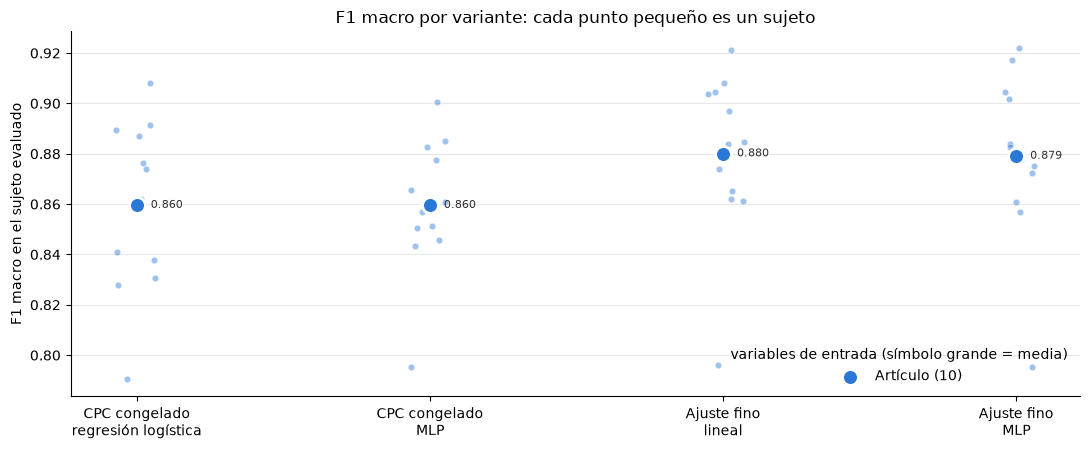

In [13]:
SET_COLORS = {"Artículo (10)": "#2a78d6", "Referencia (30)": "#eb6834"}     # azul y naranja de la paleta categórica
SET_MARKERS = {"Artículo (10)": "o", "Referencia (30)": "s"}
fig, ax = plt.subplots(figsize=(11, 4.6))
width = 0.36 if len(SET_NAMES) > 1 else 0
rng = np.random.default_rng(SEED)
for j, name in enumerate(SET_NAMES.values()):
    shift = (j - (len(SET_NAMES) - 1) / 2) * width
    for i, v in enumerate(VARIANTS):
        vals = by_subject[(name, v)].dropna().to_numpy()
        xs = i + shift + rng.uniform(-0.07, 0.07, len(vals))
        ax.scatter(xs, vals, s=22, color=SET_COLORS[name], alpha=0.45, edgecolor="white", linewidth=0.6, zorder=2)
        ax.scatter(i + shift, vals.mean(), s=130, marker=SET_MARKERS[name], color=SET_COLORS[name],
                   edgecolor="white", linewidth=2, zorder=3, label=name if i == 0 else None)
        ax.annotate(f"{vals.mean():.3f}", (i + shift, vals.mean()), xytext=(10, 0), textcoords="offset points",
                    va="center", fontsize=8, color="#333333")
ax.set_xticks(range(len(VARIANTS)), [v.replace(" · ", "\n") for v in VARIANTS])
ax.set_ylabel("F1 macro en el sujeto evaluado")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="lower right", title="variables de entrada (símbolo grande = media)")
ax.set_title("F1 macro por variante: cada punto pequeño es un sujeto")
plt.tight_layout()
plt.show()

# 8. Comparaciones emparejadas

Cada comparación usa **los mismos sujetos** y resta, persona por persona, el F1 de una variante menos el de la otra. Se reporta:

- la **diferencia media** y su intervalo de confianza del 95 % por *bootstrap* (remuestreando sujetos);
- en **cuántos sujetos** gana la primera;
- el **p-valor de Wilcoxon** (rangos con signo, emparejado). Con 12 sujetos, p < 0.05 requiere que la ventaja se repita en la mayoría de las personas.

Una diferencia se considera establecida si el intervalo no incluye el 0, la ventaja aparece en la mayoría de los sujetos y p < 0.05.

| Familia | Pregunta |
|---|---|
| **Cabezal** | ¿El MLP le gana al clasificador lineal, con el CPC congelado y con ajuste fino? |
| **Ajuste fino** | ¿Ajustar toda la red mejora sobre el CPC congelado, con cada cabezal? |
| **Variables** | ¿Las 10 variables del artículo igualan a las 30 de referencia, en cada variante? |
| **Control** | ¿La regresión logística y la capa lineal de PyTorch sobre el CPC congelado dan lo mismo? |

In [14]:
def paired(a, b):
    diff = (a - b).dropna().to_numpy()
    if len(diff) == 0:
        return {}
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
    p = wilcoxon(diff).pvalue if len(diff) > 1 and np.any(diff != 0) else np.nan
    return {"diferencia media": diff.mean(), "IC 95 % inf.": np.percentile(boot, 2.5), "IC 95 % sup.": np.percentile(boot, 97.5),
            "gana la primera": f"{(diff > 0).sum()} de {len(diff)}", "p (Wilcoxon)": p}


f1_of = lambda name, v: results[(results["conjunto"] == name) & (results["variante"] == v)].set_index("sujeto")["f1_macro"]
rows = []
for name in SET_NAMES.values():
    for fam, a, b in (("Cabezal", V_MLP0, V_LR), ("Cabezal", V_FTM, V_FTL), ("Ajuste fino", V_FTL, V_LR),
                      ("Ajuste fino", V_FTM, V_MLP0), ("Control", V_CONTROL, V_LR)):
        rows.append({"familia": fam, "conjunto": name, "comparación": f"{a}  −  {b}", **paired(f1_of(name, a), f1_of(name, b))})
if len(SET_NAMES) == 2:
    for v in VARIANTS:
        rows.append({"familia": "Variables", "conjunto": "Artículo (10) − Referencia (30)", "comparación": v,
                     **paired(f1_of("Artículo (10)", v), f1_of("Referencia (30)", v))})
comparisons = pd.DataFrame(rows).set_index(["familia", "conjunto", "comparación"])
display(comparisons.style.format({"diferencia media": "{:+.3f}", "IC 95 % inf.": "{:+.3f}", "IC 95 % sup.": "{:+.3f}",
                                  "p (Wilcoxon)": "{:.4f}"}, na_rep="—"))

## 8.1 Comparación con el CPC-GRU de 30 variables del notebook 10

El notebook 10 entrenó el mismo CPC-GRU (encoder causal, GRU de 2 capas, horizonte de 1 s, negativos del mismo sujeto, LP-FT) con las 30 variables MVNX, evaluando a los mismos sujetos 1–12 con la misma validación interna. Sus F1 por sujeto están en `notebooks/_cache/cpc10_loso_mvnx_metodos_fs12_resultados.csv`. Se comparan, persona por persona:

| Aquí (10 variables) | Notebook 10 (30 variables) |
|---|---|
| `Ajuste fino · lineal` | `ajuste fino preentrenado` (LP-FT con cabezal lineal) |
| `CPC congelado · regresión logística` | `CPC congelado (sonda)` (regresión logística con C = 1) |

**No es una comparación exacta**, por tres diferencias:

1. **Ventanas evaluadas:** el notebook 10 usa cada ensayo bimanual una vez, con los dos lados fijos (izquierdo/derecho); aquí se parte en dos ensayos por brazo. El sujeto evaluado es el mismo, pero el conjunto de ventanas no.
2. **Cabezales:** el notebook 10 usaba `LayerNorm` y dropout en el cabezal lineal y una sonda con `C` fija; aquí, estandarización, `C` elegida en la validación interna y arranque desde la regresión logística.
3. **Aleatoriedad:** el preentrenamiento CPC es distinto en cada notebook.

Sirve para saber si las 10 variables quedan **en el mismo nivel** que las 30. Si la diferencia es pequeña frente a la variación entre personas, la conclusión se sostiene; para una diferencia fina, hay que correr `"referencia_30"` aquí.

In [15]:
NB10_CSV = REPO_DIR / "notebooks" / "_cache" / "cpc10_loso_mvnx_metodos_fs12_resultados.csv"
NB10_MAP = {V_FTL: "ajuste fino preentrenado", V_LR: "CPC congelado (sonda)"}
if not NB10_CSV.exists() or "Artículo (10)" not in SET_NAMES.values():
    print("No están los resultados del notebook 10 o todavía no hay rondas del artículo: se omite la comparación.")
else:
    nb10 = pd.read_csv(NB10_CSV)
    nb10 = nb10[(nb10["g_ar"] == "GRU") & (nb10["semilla"] == SEED)]
    rows = []
    for v, m in NB10_MAP.items():
        ref = nb10[nb10["método"] == m].set_index("sujeto")["F1"]
        mine = f1_of("Artículo (10)", v)
        rows.append({"aquí": v, "notebook 10": m, "F1 medio aquí": mine.mean(), "F1 medio nb 10": ref.loc[mine.index].mean(),
                     **paired(mine, ref)})
    display(pd.DataFrame(rows).set_index(["aquí", "notebook 10"]).style.format(
        {"F1 medio aquí": "{:.3f}", "F1 medio nb 10": "{:.3f}", "diferencia media": "{:+.3f}", "IC 95 % inf.": "{:+.3f}",
         "IC 95 % sup.": "{:+.3f}", "p (Wilcoxon)": "{:.4f}"}, na_rep="—"))
    per_subject = pd.DataFrame({"10 variables · ajuste fino lineal": f1_of("Artículo (10)", V_FTL),
                                "30 variables (nb 10) · ajuste fino": nb10[nb10["método"] == NB10_MAP[V_FTL]].set_index("sujeto")["F1"]})
    display(per_subject.dropna().T.style.format("{:.3f}"))

,,F1 medio aquí,F1 medio nb 10,diferencia media,IC 95 % inf.,IC 95 % sup.,gana la primera,p (Wilcoxon)
aquí,notebook 10,,,,,,,
Ajuste fino · lineal,ajuste fino preentrenado,0.880,0.878,+0.002,-0.009,+0.012,7 de 12,0.5693
CPC congelado · regresión logística,CPC congelado (sonda),0.860,0.820,+0.040,+0.019,+0.063,9 de 12,0.0068


sujeto,1,2,3,4,5,6,7,8,9,10,11,12
10 variables · ajuste fino lineal,0.884,0.796,0.885,0.861,0.921,0.897,0.862,0.874,0.904,0.865,0.908,0.905
30 variables (nb 10) · ajuste fino,0.879,0.835,0.876,0.879,0.897,0.901,0.884,0.847,0.891,0.870,0.896,0.886


# 9. Curva de aprendizaje: ¿ayudarían más sujetos?

El artículo entrena con 13 sujetos; aquí cada ronda entrena con 10. En lugar de usar los sujetos 13 y 14 (reservados para la prueba final), se responde la pregunta **hacia abajo**: se repiten las mismas rondas con 4, 6 y 8 de los 10 sujetos de entrenamiento. Los sujetos evaluados, la validación interna, la semilla y las ventanas son los mismos; sólo cambia cuántas personas se usan para entrenar (sección 5).

- Si el F1 **sigue subiendo** entre 8 y 10 sujetos, es probable que con 13 (como el artículo) mejore más: el modelo está limitado por la cantidad de personas.
- Si la curva **se aplana** antes de 10, más sujetos ayudarían poco y conviene buscar mejoras en otra parte (variables, escala temporal, modelo).
- La curva también dice si el MLP necesita más datos que el clasificador lineal: si la brecha entre los dos cambia con el número de sujetos.

Por defecto la curva se corre sólo con las 10 variables del artículo (`CURVA_SETS` en la configuración). El punto de 10 sujetos son las rondas principales de la sección 6.

In [16]:
t_start = time.time()
log(f"curva de aprendizaje: {CURVA_SIZES} sujetos × {len(FOLDS)} rondas × {CURVA_SETS}")
for set_name in CURVA_SETS:
    for n_train in CURVA_SIZES:
        for held_out in FOLDS:
            run_round(set_name, held_out, n_train)
log(f"fin de la curva: {(time.time() - t_start) / 3600:.2f} h en esta ejecución")

2026-11-12 22:31 | curva de aprendizaje: (4, 6, 8) sujetos × 12 rondas × ['articulo_10']
2026-11-12 22:31 | fin de la curva: 0.00 h en esta ejecución


In [17]:
curve_rows = []
for set_name in CURVA_SETS:
    for n_train in (*CURVA_SIZES, None):
        for held_out in FOLDS:
            path = round_path(set_name, held_out, n_train)
            if not path.exists():
                continue
            r = json.loads(path.read_text())
            curve_rows += [{"conjunto": INPUT_SETS[set_name]["nombre"], "sujetos": r["n_train"], "sujeto": held_out,
                            "variante": v, "f1_macro": r["metricas"][v]["f1_macro"]} for v in (*VARIANTS, V_CONTROL)]
curve = pd.DataFrame(curve_rows, columns=["conjunto", "sujetos", "sujeto", "variante", "f1_macro"])
if curve.empty:
    print("No hay rondas de la curva (CURVA_SETS vacío o sin terminar): se omiten la tabla y la gráfica.")
else:
    # Sólo los sujetos evaluados que ya tienen todos los tamaños, para que cada punto promedie a las mismas personas
    complete = curve.groupby(["conjunto", "sujeto"])["sujetos"].nunique()
    complete = complete[complete == curve["sujetos"].nunique()].index
    curve = curve.set_index(["conjunto", "sujeto"]).loc[complete].reset_index()
    print(f"Sujetos evaluados con la curva completa: {curve['sujeto'].nunique()}")

    curve_table = curve.pivot_table(index=["conjunto", "variante"], columns="sujetos", values="f1_macro", aggfunc=["mean", "std"])
    display(curve_table.style.format("{:.3f}"))

Sujetos evaluados con la curva completa: 12


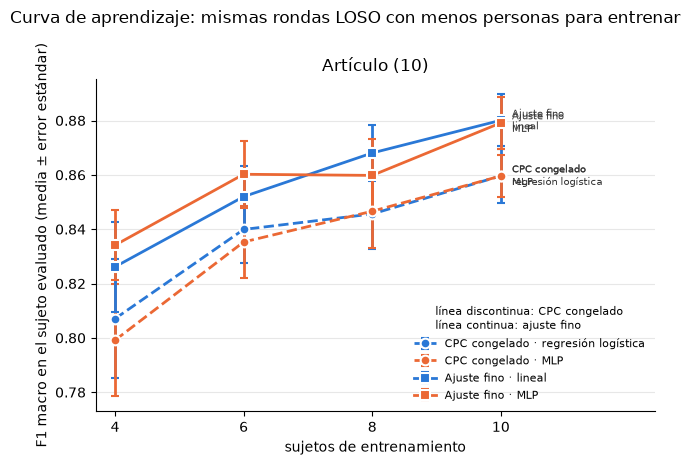

In [18]:
if not curve.empty:
    HEAD_COLORS = {"lineal": "#2a78d6", "mlp": "#eb6834"}           # azul y naranja de la paleta categórica
    STYLE = {V_LR: ("lineal", "--", "o"), V_MLP0: ("mlp", "--", "o"), V_FTL: ("lineal", "-", "s"), V_FTM: ("mlp", "-", "s")}
    names = curve["conjunto"].unique()
    fig, axes = plt.subplots(1, len(names), figsize=(6.5 * len(names), 4.6), squeeze=False)
    for ax, name in zip(axes[0], names):
        part = curve[curve["conjunto"] == name]
        for v, (kind, ls, marker) in STYLE.items():
            g = part[part["variante"] == v].groupby("sujetos")["f1_macro"]
            mean, se = g.mean(), g.std() / np.sqrt(g.count())
            ax.errorbar(mean.index, mean.values, yerr=se.values, color=HEAD_COLORS[kind], ls=ls, marker=marker, ms=7, lw=2,
                        capsize=3, label=v, mec="white", mew=1.5)
            ax.annotate(v.replace(" · ", "\n"), (mean.index[-1], mean.values[-1]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=7.5, color="#333333")
        ax.set_xticks(sorted(part["sujetos"].unique()))
        ax.set_xlim(right=part["sujetos"].max() + 2.4)
        ax.set(xlabel="sujetos de entrenamiento", ylabel="F1 macro en el sujeto evaluado (media ± error estándar)", title=name)
        ax.grid(axis="y", alpha=0.3)
    axes[0][0].legend(frameon=False, fontsize=8, loc="lower right", title="línea discontinua: CPC congelado\nlínea continua: ajuste fino",
                      title_fontsize=8)
    fig.suptitle("Curva de aprendizaje: mismas rondas LOSO con menos personas para entrenar", y=1.0)
    plt.tight_layout()
    plt.show()

**Comparaciones emparejadas de la curva.** Para cada tamaño: la ventaja del MLP sobre el lineal (con el CPC congelado y con ajuste fino) y cuánto se pierde con ese tamaño frente a los 10 sujetos.

In [19]:
if not curve.empty:
    f1_curve = lambda name, v, n: curve[(curve["conjunto"] == name) & (curve["variante"] == v) & (curve["sujetos"] == n)].set_index("sujeto")["f1_macro"]
    n_max, rows = curve["sujetos"].max(), []
    for name in names:
        for n in sorted(curve["sujetos"].unique()):
            for a, b in ((V_MLP0, V_LR), (V_FTM, V_FTL)):
                rows.append({"conjunto": name, "sujetos": n, "comparación": f"{a}  −  {b}", **paired(f1_curve(name, a, n), f1_curve(name, b, n))})
            if n < n_max:
                for v in VARIANTS:
                    rows.append({"conjunto": name, "sujetos": n, "comparación": f"{v}: {n} − {n_max} sujetos",
                                 **paired(f1_curve(name, v, n), f1_curve(name, v, n_max))})
    display(pd.DataFrame(rows).set_index(["conjunto", "sujetos", "comparación"]).style.format(
        {"diferencia media": "{:+.3f}", "IC 95 % inf.": "{:+.3f}", "IC 95 % sup.": "{:+.3f}", "p (Wilcoxon)": "{:.4f}"}, na_rep="—"))

# 10. LOSO con 14 sujetos: entrenar con 13, como el artículo

**Qué hace el artículo.** Lo que el artículo llama LOSO (sección 3.3) es **una sola ronda**: deja fuera al sujeto 11, entrena con 1 a 13 de los otros sujetos y evalúa siempre en el 11:

> *"we adopted the Leave-One-Subject-Out (LOSO) technique to assess the classification performances obtained training the two networks with 13 different datasets with increasing subject numerosity (1 to 13) and testing on the fourteenth subject data not considered during training."*

Su mejor resultado, con 13 sujetos, es F1 macro **90.3 %** (BiLSTM, sección 4.3 y resumen; la Tabla 5 dice 90.6 %).

**Qué se hace aquí.** Un LOSO completo con los **14 sujetos**: cada sujeto se evalúa por turno y se entrena con **los otros 13**, el mismo número de sujetos que el artículo. Después se mira aparte al **sujeto 11** para comparar con el artículo (sección 10.2).

> ⚠️ **Esta sección usa los sujetos 13 y 14**, que estaban reservados para la prueba final. Desde aquí ya no son una prueba limpia: entran al entrenamiento de 12 de las 14 rondas.

**Cómo se entrena con 13 sin perder la validación interna.** Hasta ahora, cada ronda usaba un sujeto de validación interna para elegir la `C` de la regresión logística y las épocas (de CPC y del ajuste fino), y ese sujeto no entraba al entrenamiento. Para llegar a 13 sujetos de entrenamiento, cada ronda tiene dos etapas:

1. **Selección:** entrena con 12 sujetos y usa al decimotercero como validación interna para elegir la época de CPC, la `C` y la época del ajuste fino (igual que en las secciones 6–9).
2. **Reentrenamiento:** vuelve a entrenar desde cero con **los 13 sujetos**, con los valores elegidos en la etapa 1 fijos (sin parada temprana). El sujeto evaluado nunca participa en ninguna de las dos etapas.

Así cada ronda da dos resultados: con **12** y con **13** sujetos de entrenamiento. Se suman a la curva de la sección 9 (4, 6, 8 y 10 sujetos).

**Variantes.** Sólo **CPC congelado · regresión logística** y **ajuste fino · lineal**. El MLP no se incluye: en la sección 8 empató con el cabezal lineal (diferencia −0.001 con ajuste fino, gana en 6 de 12 sujetos) y en la sección 9 no le ganó con ningún número de sujetos. Incluirlo duplicaría el tiempo sin una pregunta abierta que responder.

In [20]:
ALL_SUBJECTS = tuple(range(1, 15))     # LOSO de esta sección: los 14 sujetos (incluye los reservados 13 y 14)
L14_DIR = RUN_DIR / "articulo_10" / "loso14"
L14_FOLDS = (11, 13) if QUICK else ALL_SUBJECTS
V12_LR, V12_FT = "12 sujetos · regresión logística", "12 sujetos · ajuste fino lineal"
V13_LR, V13_FT = "13 sujetos · regresión logística", "13 sujetos · ajuste fino lineal"
L14_VARIANTS = (V12_LR, V12_FT, V13_LR, V13_FT)


def inner_val_14(held_out):
    """El sujeto siguiente de la lista de 14 (de forma circular) es la validación interna de la etapa de selección."""
    i = ALL_SUBJECTS.index(held_out)
    return ALL_SUBJECTS[(i + 1) % len(ALL_SUBJECTS)]


def prepare_round_14(held_out, train_subjects, val_subject=None):
    """Como prepare_round, pero con cualquier lista de sujetos de 1–14; sin val_subject no hay validación interna."""
    global S_T
    spec = INPUT_SETS["articulo_10"]
    assert held_out not in train_subjects and val_subject not in train_subjects
    train = balance(sup_index[sup_index["subject"].isin(train_subjects)])
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "held": eval_set(sup_index[sup_index["subject"] == held_out])}
    if val_subject is not None:
        sets["val"] = eval_set(sup_index[sup_index["subject"] == val_subject])
    n_steps = max(1, len(cpc_index[cpc_index["subject"].isin(train_subjects)]) // CPC_BATCH)
    scaler = fit_scaler(spec, train_subjects)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, spec).T)).to(DEVICE)
    return {"set": "articulo_10", "held_out": held_out, "inner_val": val_subject, "train_subjects": tuple(train_subjects),
            "sets": sets, "n_steps": min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps,
            "n_channels": spec["signals"].shape[1], "scaler": scaler}


def train_cpc_fixed(rnd, epochs, seed=SEED):
    """Preentrenamiento CPC con un número fijo de épocas (las elegidas en la etapa de selección)."""
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    for _ in range(epochs):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
    model.eval()
    return model, {"epochs": epochs, "minutes": (time.time() - t0) / 60}


def finetune_fixed(model, sets, epochs, seed):
    """Ajuste fino (etapa FT de LP-FT) con un número fijo de épocas; 0 épocas deja el cabezal de la regresión logística."""
    t0 = time.time()
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng = np.random.default_rng(seed)
    for _ in range(epochs):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
    model.eval()
    return {"epochs": epochs, "minutes": (time.time() - t0) / 60}


def run_round_14(held_out, seed=SEED):
    path = L14_DIR / f"ronda_s{held_out:02d}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    val_subject = inner_val_14(held_out)
    train13 = tuple(s for s in ALL_SUBJECTS if s != held_out)
    train12 = tuple(s for s in train13 if s != val_subject)
    preds, info = {}, {}

    # ---- Etapa 1, selección: 12 sujetos de entrenamiento + 1 de validación interna ----
    rnd = prepare_round_14(held_out, train12, val_subject)
    sets = rnd["sets"]
    cpc_model, info["cpc_12"] = train_cpc(rnd, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    feats = {part: cpc_features(cpc_model, sets[part]["starts"]) for part in ("ft_train", "val", "held")}
    lr = fit_logreg(feats, sets)
    preds[V12_LR] = lr["model"].predict(feats["held"].float().cpu().numpy())
    info[V12_LR] = {k: lr[k] for k in ("C", "f1_val", "converged", "minutes")}
    torch.manual_seed(seed)
    linear = head_from_logreg(CPCClassifier(cpc_model, "lineal").to(DEVICE).eval(), lr["model"])
    with torch.no_grad():
        start_f1 = f1_score(sets["val"]["y"], linear.head(feats["val"]).argmax(1).cpu().numpy(), average="macro")
    info[V12_FT] = finetune(linear, sets, start_f1, seed)
    preds[V12_FT] = predict(linear, sets["held"]["starts"])
    y = sets["held"]["y"]
    del cpc_model, linear, feats, cpc_state

    # ---- Etapa 2, reentrenamiento: los 13 sujetos, con las épocas y la C de la etapa 1 fijas ----
    rnd13 = prepare_round_14(held_out, train13)
    sets13 = rnd13["sets"]
    assert np.array_equal(sets13["held"]["y"], y)
    cpc13, info["cpc_13"] = train_cpc_fixed(rnd13, info["cpc_12"]["best_epoch"], seed)
    feats13 = {part: cpc_features(cpc13, sets13[part]["starts"]) for part in ("ft_train", "held")}
    t_lr = time.time()
    lr13 = make_pipeline(StandardScaler(), LogisticRegression(C=info[V12_LR]["C"], max_iter=LOGREG_MAX_ITER,
                                                              class_weight="balanced"))
    lr13.fit(feats13["ft_train"].float().cpu().numpy(), sets13["ft_train"]["y"])
    preds[V13_LR] = lr13.predict(feats13["held"].float().cpu().numpy())
    info[V13_LR] = {"C": info[V12_LR]["C"], "converged": bool(lr13[-1].n_iter_.max() < LOGREG_MAX_ITER),
                    "minutes": (time.time() - t_lr) / 60}
    torch.manual_seed(seed)
    linear13 = head_from_logreg(CPCClassifier(cpc13, "lineal").to(DEVICE).eval(), lr13)
    info[V13_FT] = finetune_fixed(linear13, sets13, info[V12_FT]["best_epoch"], seed)
    preds[V13_FT] = predict(linear13, sets13["held"]["starts"])

    result = {"held_out": held_out, "inner_val": val_subject, "train12": list(train12), "train13": list(train13),
              "seed": seed, "balanceo": BALANCEO, "metricas": {v: metrics(y, p) for v, p in preds.items()}, "info": info,
              "minutos": (time.time() - t0) / 60, "index": sets["held"]["index"].tolist(), "y": y.tolist(),
              "pred": {v: np.asarray(p).tolist() for v, p in preds.items()}}
    torch.save({"cpc_13": cpc13.state_dict(), V13_FT: linear13.state_dict()}, path.with_suffix(".pt"))
    joblib.dump(lr13, path.with_suffix(".joblib"))
    path.write_text(json.dumps(result))
    log(f"LOSO-14 · sujeto {held_out:2d} | " + " | ".join(f"{v}: {result['metricas'][v]['f1_macro']:.3f}" for v in L14_VARIANTS)
        + f" | {result['minutos']:.1f} min")
    del cpc13, linear13, feats13
    return result


t_start = time.time()
log(f"LOSO-14: {len(L14_FOLDS)} rondas (12 y 13 sujetos de entrenamiento)")
for held_out in L14_FOLDS:
    run_round_14(held_out)
log(f"fin del LOSO-14: {(time.time() - t_start) / 3600:.2f} h en esta ejecución")

2026-11-12 22:31 | LOSO-14: 14 rondas (12 y 13 sujetos de entrenamiento)
2026-11-12 22:31 | fin del LOSO-14: 0.00 h en esta ejecución


## 10.1 Resultados con 12 y 13 sujetos de entrenamiento

F1 macro de cada sujeto evaluado. Las filas de resumen separan a los sujetos 1–12 (los de las secciones 6–9) de los sujetos 13 y 14, que se evalúan por primera vez.

In [21]:
l14 = {r["held_out"]: r for r in (json.loads(p.read_text()) for p in sorted(L14_DIR.glob("ronda_*.json")))}
assert l14, "Todavía no hay rondas del LOSO-14."
f1_14 = pd.DataFrame({v: {s: r["metricas"][v]["f1_macro"] for s, r in l14.items()} for v in L14_VARIANTS})
f1_14.index.name = "sujeto"
cv_part, new_part = f1_14.loc[f1_14.index.isin(CV_SUBJECTS)], f1_14.loc[~f1_14.index.isin(CV_SUBJECTS)]
summary_14 = pd.concat([f1_14, f1_14.agg(["mean", "std", "min"]).rename(index={"mean": "media (todos)", "std": "desv. (todos)",
                                                                              "min": "peor (todos)"}),
                        cv_part.mean().rename("media sujetos 1–12").to_frame().T,
                        new_part.mean().rename("media sujetos 13–14").to_frame().T])
display(summary_14.style.format("{:.3f}", na_rep="—").highlight_max(axis=1, color="#d8e8f8"))

rows = []
for a, b in ((V13_FT, V12_FT), (V13_LR, V12_LR), (V13_FT, V13_LR), (V12_FT, V12_LR)):
    rows.append({"comparación": f"{a}  −  {b}", "sujetos": "1–14", **paired(f1_14[a], f1_14[b])})
# Mismos sujetos 1–12 con 10 sujetos de entrenamiento (sección 6)
main_runs = runs.get("articulo_10", {})
if main_runs:
    ten = {V_LR: f1_of("Artículo (10)", V_LR), V_FTL: f1_of("Artículo (10)", V_FTL)}
    ten_name = {V_LR: "10 sujetos · regresión logística", V_FTL: "10 sujetos · ajuste fino lineal"}
    for a, b in ((V13_FT, V_FTL), (V13_LR, V_LR), (V12_FT, V_FTL)):
        rows.append({"comparación": f"{a}  −  {ten_name[b]} (sección 6)", "sujetos": "1–12",
                     **paired(f1_14[a], ten[b])})        # se emparejan por sujeto; 13 y 14 quedan fuera
display(pd.DataFrame(rows).set_index(["comparación", "sujetos"]).style.format(
    {"diferencia media": "{:+.3f}", "IC 95 % inf.": "{:+.3f}", "IC 95 % sup.": "{:+.3f}", "p (Wilcoxon)": "{:.4f}"}, na_rep="—"))

info_14 = pd.DataFrame([{"sujeto": s, "val. interna": r["inner_val"], "época CPC": r["info"]["cpc_12"]["best_epoch"],
                         "C": r["info"][V12_LR]["C"], "época ajuste fino": r["info"][V12_FT]["best_epoch"],
                         "min ronda": r["minutos"]} for s, r in l14.items()]).set_index("sujeto")
print("Valores elegidos en la etapa de selección (se usan fijos en el reentrenamiento con 13):")
display(info_14.T.round(2))

,12 sujetos · regresión logística,12 sujetos · ajuste fino lineal,13 sujetos · regresión logística,13 sujetos · ajuste fino lineal
1,0.885,0.885,0.871,0.871
2,0.794,0.791,0.795,0.797
3,0.842,0.873,0.837,0.852
4,0.866,0.886,0.870,0.891
5,0.904,0.913,0.911,0.915
6,0.857,0.886,0.871,0.892
7,0.855,0.867,0.865,0.868
8,0.900,0.914,0.895,0.893
9,0.883,0.908,0.884,0.903
10,0.839,0.839,0.832,0.851


,,diferencia media,IC 95 % inf.,IC 95 % sup.,gana la primera,p (Wilcoxon)
comparación,sujetos,,,,,
13 sujetos · ajuste fino lineal − 12 sujetos · ajuste fino lineal,1–14,-0.002,-0.008,+0.003,8 de 14,0.8552
13 sujetos · regresión logística − 12 sujetos · regresión logística,1–14,+0.000,-0.003,+0.004,7 de 14,0.9032
13 sujetos · ajuste fino lineal − 13 sujetos · regresión logística,1–14,+0.011,+0.005,+0.015,12 de 14,0.0037
12 sujetos · ajuste fino lineal − 12 sujetos · regresión logística,1–14,+0.013,+0.008,+0.018,11 de 14,0.0030
13 sujetos · ajuste fino lineal − 10 sujetos · ajuste fino lineal (sección 6),1–12,-0.001,-0.010,+0.008,6 de 12,0.8501
13 sujetos · regresión logística − 10 sujetos · regresión logística (sección 6),1–12,+0.011,+0.004,+0.018,10 de 12,0.0161
12 sujetos · ajuste fino lineal − 10 sujetos · ajuste fino lineal (sección 6),1–12,+0.002,-0.007,+0.012,7 de 12,0.9697


Valores elegidos en la etapa de selección (se usan fijos en el reentrenamiento con 13):


sujeto,1,2,3,4,5,6,7,8,9,10,11,12,13,14
val. interna,2.00,3.00,4.00,5.00,6.00,7.0,8.00,9.00,10.00,11.00,12.00,13.00,14.00,1.00
época CPC,16.00,2.00,4.00,12.00,18.00,10.0,20.00,20.00,8.00,14.00,16.00,20.00,14.00,16.00
C,0.10,1.00,1.00,0.30,0.03,0.3,1.00,0.03,0.30,0.10,0.03,0.30,0.01,0.30
época ajuste fino,0.00,5.00,5.00,11.00,6.00,4.0,2.00,9.00,14.00,1.00,10.00,3.00,6.00,10.00
min ronda,6.43,5.65,6.15,11.43,10.07,7.5,8.37,11.93,12.22,7.02,11.75,9.02,9.78,12.44


## 10.2 El sujeto 11: comparación con el artículo

El artículo evalúa sólo al sujeto 11. Aquí se junta todo lo que hay para ese sujeto: la curva de la sección 9 (4, 6, 8 y 10 sujetos de entrenamiento) y las dos etapas de esta sección (12 y 13). Del artículo se toman el F1 macro con 13 sujetos (sección 4.3) y el F1 por actividad de su **Tabla 4** (LOSO con 13 sujetos).

**No es una comparación exacta:**

- **Escala temporal:** el artículo usa ventanas de 1 s a ~240 Hz, sin traslape; aquí, 4 s a 12 Hz con una ventana cada 0.5 s.
- **Ensayos y balanceo:** el artículo usa menos ensayos (MMH a una mano sólo del brazo derecho, bimanuales sólo del izquierdo) y balancea submuestreando `N` y agregando copias con ruido de las clases pequeñas (sección 2).
- **Modelo:** el artículo entrena una BiLSTM supervisada desde cero; aquí es CPC-GRU con preentrenamiento sin etiquetas.
- **Ventanas evaluadas:** las del sujeto 11 no son las mismas en los dos trabajos, por la ventana y por la selección de ensayos.

Sujeto 11 — F1 macro según el número de sujetos de entrenamiento:


,regresión logística,ajuste fino lineal,artículo (BiLSTM)
sujetos de entrenamiento,,,
4,0.885,0.879,—
6,0.893,0.893,—
8,0.890,0.890,—
10,0.908,0.908,—
12,0.909,0.916,—
13,0.909,0.910,0.903


Sujeto 11 — F1 por actividad:


,aquí: 13 sujetos · ajuste fino lineal,"artículo: BiLSTM, 13 sujetos (Tabla 4)",diferencia (aquí − artículo)
N,0.960,0.891,+0.069
LF,0.864,0.903,-0.039
K,0.951,0.923,+0.028
PT,0.868,0.840,+0.028
LT,0.905,0.945,-0.040
W,0.904,0.934,-0.030
PF,0.916,0.888,+0.028
F1 macro,0.910,0.903,+0.007


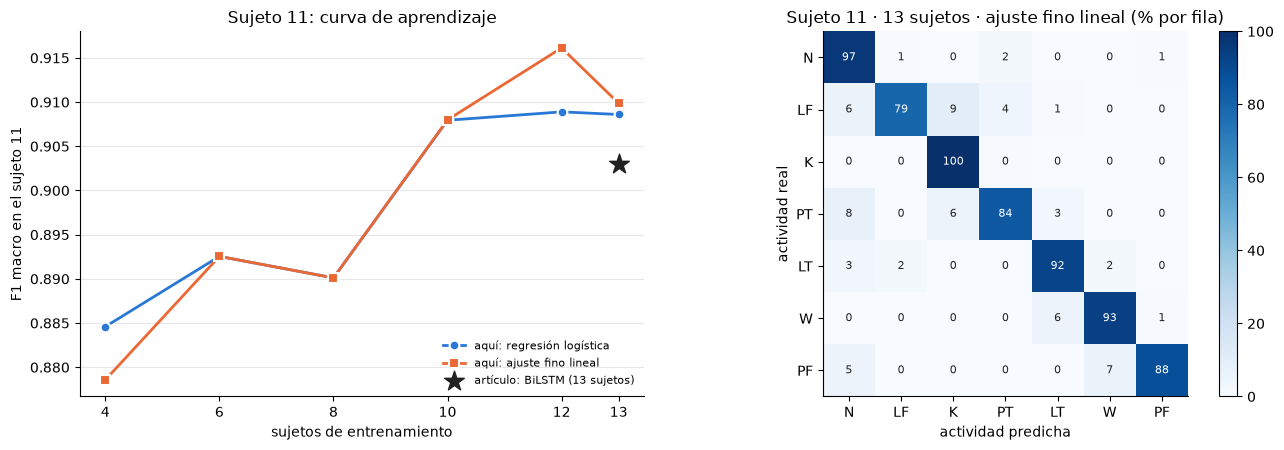

In [22]:
S11 = 11
PAPER_S11_F1 = 0.903          # BiLSTM, 13 sujetos (sección 4.3 y resumen; la Tabla 5 dice 0.906)
PAPER_TABLE4 = {"N": 0.891, "LF": 0.903, "K": 0.923, "PT": 0.840, "LT": 0.945, "W": 0.934, "PF": 0.888}   # BiLSTM

curve11 = []
for n_train in (*CURVA_SIZES, None):
    path = round_path("articulo_10", S11, n_train)
    if path.exists():
        r = json.loads(path.read_text())
        curve11.append({"sujetos de entrenamiento": r["n_train"], "regresión logística": r["metricas"][V_LR]["f1_macro"],
                        "ajuste fino lineal": r["metricas"][V_FTL]["f1_macro"]})
if S11 in l14:
    for n, (a, b) in ((12, (V12_LR, V12_FT)), (13, (V13_LR, V13_FT))):
        curve11.append({"sujetos de entrenamiento": n, "regresión logística": l14[S11]["metricas"][a]["f1_macro"],
                        "ajuste fino lineal": l14[S11]["metricas"][b]["f1_macro"]})
curve11 = pd.DataFrame(curve11).sort_values("sujetos de entrenamiento").set_index("sujetos de entrenamiento")
curve11["artículo (BiLSTM)"] = np.nan
curve11.loc[13, "artículo (BiLSTM)"] = PAPER_S11_F1
print("Sujeto 11 — F1 macro según el número de sujetos de entrenamiento:")
display(curve11.style.format("{:.3f}", na_rep="—"))

if S11 in l14:
    r = l14[S11]
    y, pred = np.asarray(r["y"]), np.asarray(r["pred"][V13_FT])
    per_act = pd.DataFrame({"aquí: 13 sujetos · ajuste fino lineal": f1_score(y, pred, average=None, labels=range(len(LABELS))),
                            "artículo: BiLSTM, 13 sujetos (Tabla 4)": [PAPER_TABLE4[l] for l in LABELS]}, index=LABELS)
    per_act["diferencia (aquí − artículo)"] = per_act.iloc[:, 0] - per_act.iloc[:, 1]
    per_act.loc["F1 macro"] = [f1_score(y, pred, average="macro"), PAPER_S11_F1, f1_score(y, pred, average="macro") - PAPER_S11_F1]
    print("Sujeto 11 — F1 por actividad:")
    display(per_act.style.format("{:+.3f}", subset=["diferencia (aquí − artículo)"])
            .format("{:.3f}", subset=per_act.columns[:2]))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
    ax = axes[0]
    for col, color, marker in (("regresión logística", "#2a78d6", "o"), ("ajuste fino lineal", "#eb6834", "s")):
        ax.plot(curve11.index, curve11[col], color=color, marker=marker, lw=2, ms=7, mec="white", mew=1.5, label=f"aquí: {col}")
    ax.scatter([13], [PAPER_S11_F1], marker="*", s=220, color="#222222", zorder=3, label="artículo: BiLSTM (13 sujetos)")
    ax.set(xlabel="sujetos de entrenamiento", ylabel="F1 macro en el sujeto 11", title="Sujeto 11: curva de aprendizaje")
    ax.set_xticks(curve11.index)
    ax.grid(axis="y", alpha=0.3); ax.legend(frameon=False, fontsize=8, loc="lower right")
    cm = confusion_matrix(y, pred, labels=range(len(LABELS)), normalize="true") * 100
    ax = axes[1]
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 60 else "#222222")
    ax.set_xticks(range(len(LABELS)), LABELS); ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set(xlabel="actividad predicha", ylabel="actividad real", title="Sujeto 11 · 13 sujetos · ajuste fino lineal (% por fila)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

## 10.3 Conclusiones de la sección (corrida del 11 de noviembre de 2026)

**F1 macro medio, LOSO con los 14 sujetos:**

| Variante | 12 sujetos de entrenamiento | 13 sujetos de entrenamiento |
|---|---|---|
| CPC congelado · regresión logística | 0.872 ± 0.032 | 0.873 ± 0.033 |
| **Ajuste fino · lineal** | **0.885** ± 0.035 | **0.883** ± 0.033 |

**1. Pasar de 12 a 13 sujetos no cambia nada.**
- Ajuste fino lineal: −0.002 [−0.008, +0.003]; gana en 8 de 14 sujetos (p = 0.86).
- Regresión logística: +0.000 [−0.003, +0.004]; gana en 7 de 14 (p = 0.90).

El reentrenamiento con 13 no tiene validación propia: usa las épocas y la `C` elegidas con 12. Esto puede costar un poco, pero no explica una ganancia nula también en la regresión logística, que no depende de las épocas del ajuste fino.

**2. Con ajuste fino, la curva ya se aplanó en 10 sujetos.** Sobre los sujetos 1–12, comparados con las rondas principales:

| Sujetos de entrenamiento | 4 | 6 | 8 | 10 | 12 | 13 |
|---|---|---|---|---|---|---|
| Ajuste fino · lineal | 0.826 | 0.852 | 0.868 | 0.880 | 0.882 | 0.879 |
| CPC congelado · regresión logística | 0.807 | 0.840 | 0.846 | 0.860 | 0.870 | 0.871 |

- **Ajuste fino lineal, 13 − 10 sujetos:** −0.001 [−0.010, +0.008] (p = 0.85). Con 12 − 10: +0.002 (p = 0.97).
- **Regresión logística, 13 − 10 sujetos:** +0.011 [+0.004, +0.018]; gana en 10 de 12 (p = 0.016). La representación congelada sí sigue mejorando con más personas, pero el ajuste fino ya recuperaba esa ganancia con 10 sujetos.

La hipótesis de la sección 9 ("con 12 o 13 sujetos se ganaría ~+0.01 más") **no se cumple para el ajuste fino**: la ganancia por cada 2 sujetos siguió bajando (+0.026, +0.016, +0.012) hasta llegar a cero. Más personas del mismo protocolo ya no ayudan a este modelo. Para mejorar habría que cambiar otra cosa: la escala temporal, las variables o la arquitectura.

**3. El ajuste fino sigue ayudando:** +0.011 con 13 sujetos (gana en 12 de 14; p = 0.004) y +0.013 con 12 (11 de 14; p = 0.003). La ventaja es más pequeña que con 10 sujetos (+0.020), porque la regresión logística sube y el ajuste fino no.

**4. Los sujetos 13 y 14 rinden como los demás, o mejor.** Con 13 sujetos y ajuste fino lineal: 0.902 y 0.913, frente a una media de 0.879 en los sujetos 1–12. Todo el diseño (variables, cabezal, ajuste fino desde la regresión logística, pesos por clase) se eligió sólo con los sujetos 1–12, así que estos dos valores funcionan como la prueba final prevista: **el modelo generaliza a las dos personas reservadas**. Desde ahora ya no son una prueba limpia.

**5. Sujeto 11 frente al artículo: 0.910 aquí, 0.903 en el artículo (BiLSTM, 13 sujetos).**
- Por actividad: mejor en `N` (+0.069), `K`, `PT` y `PF` (+0.028 cada una); peor en `LF` (−0.039), `LT` (−0.040) y `W` (−0.030).
- **No es una ventaja demostrada.** Es una sola persona, una sola semilla y un protocolo distinto (ventanas de 4 s a 12 Hz, validación interna, otro modelo); la diferencia de +0.007 es mucho menor que la variación entre sujetos (0.79–0.92).
- El sujeto 11 es de los fáciles para este modelo: con 10 sujetos ya daba 0.908, y con 4, 0.879. Por eso **la media de los 14 sujetos (0.883) es mejor estimación del desempeño** que el resultado de una sola persona, y es la cifra que el artículo no reporta.
- Lo que sí se puede decir: con las mismas 10 variables y los mismos 13 sujetos de entrenamiento, el CPC-GRU con cabezal lineal alcanza en el sujeto 11 el nivel que reporta el artículo.

# 11. A 240 Hz con ventanas de 1 s, como el artículo

Hasta aquí todo se hizo a **12 Hz con ventanas de 4 s**. El artículo usa la frecuencia original del MVNX (**~240 Hz**) y ventanas de **1 s sin traslape**: su entrada es de 10 × 240 (sección 3.1 y Tabla 3). Esta sección repite el LOSO con 14 sujetos de la sección 10 con esa escala temporal: **las mismas 10 variables, los mismos sujetos y la misma frecuencia que el artículo**.

**Datos.** El notebook `07_Sincronizacion_sEMG_MVNX` volvió a leer los MVNX crudos con `SYNC_FS=240` y `SYNC_COLUMNS=articulo`, y exportó a `notebooks/_cache/sync/fs240_articulo`. La alineación sEMG–MVNX y las etiquetas se calculan igual que a 12 Hz. Sólo se exportan las 28 columnas MVNX que usan las 10 variables: las 782 no caben en memoria a 240 Hz (~21 GB). A 240 Hz el filtro antialias corta en 96 Hz, así que la aceleración de la mano ya no se suaviza como a 12 Hz (corte en 4.8 Hz). Su notebook ejecutado está en `checkpoints/07_sync_fs240_articulo_ejecutado.ipynb`.

**Qué cambia respecto de la sección 10:**

| Elemento | 12 Hz (secciones 6–10) | 240 Hz (esta sección) | Por qué |
|---|---|---|---|
| Ventana para clasificar | 48 pasos = 4 s | **240 pasos = 1 s**, como el artículo | La entrada del artículo |
| Ventanas evaluadas | una cada 0.5 s | **una cada 1 s, sin traslape** (también la validación interna) | Como el artículo. En el entrenamiento se usa una cada 0.5 s, como a 12 Hz |
| Codificador CPC | 3 convoluciones sin reducción: 12 Hz → 12 Hz | Las mismas 3 capas (32, 64, 128) con pasos 2, 5 y 1: **240 Hz → 24 Hz** | Sin reducción, 12 pasos serían 50 ms y predecir el futuro sería trivial |
| Horizontes CPC | K = 1–12: 12 pasos de 83 ms = **1 s** | Dos variantes: **K = 12** (12 pasos de 42 ms = **0.5 s**) y **K = 24** (24 pasos = **1 s**, el mismo horizonte en el tiempo que a 12 Hz) | Sin reducción, 12 pasos serían 50 ms. Con K = 24 el CPC predice tan lejos como a 12 Hz |
| Preentrenamiento CPC | tramos de 4 s | tramos de **4 s** (960 muestras, 96 pasos internos) | Deja espacio para predecir 12 pasos. La GRU después clasifica ventanas de 1 s |
| Etiqueta | la del instante final | igual | Convención del proyecto |
| Protocolo | LOSO-14 en dos etapas (selección con 12 + reentrenamiento con 13) | igual | Para comparar sujeto por sujeto con la sección 10 |

**Orden de ejecución.** Primero se corrió el **sujeto 11** con K = 12, la ronda del artículo, para medir el tiempo (~10 min por ronda). Después, el LOSO con los 14 sujetos con K = 12 y luego con K = 24. La variable de entorno `NB12_FS240` fija qué sujetos se corren (por ejemplo, `NB12_FS240=11`) y `NB12_FS240_K` qué K (por ejemplo, `NB12_FS240_K=12`). Sin ellas se corren los 14 sujetos, empezando por el 11, con las dos K. Las rondas ya guardadas no se repiten.

In [23]:
## 11.1 Datos a 240 Hz: las mismas 10 variables
FS_240 = 240
SYNC_240 = REPO_DIR / "notebooks" / "_cache" / "sync" / "fs240_articulo"
WIN_240, CPC_WIN_240 = 240, 960                  # 1 s para clasificar (como el artículo); 4 s para el preentrenamiento CPC
SUP_HOP_240, CPC_HOP_240 = 120, 480              # una ventana etiquetada cada 0.5 s (entrenamiento) y una sin etiqueta cada 2 s
ENC_KERNELS_240, ENC_STRIDES_240 = (4, 10, 3), (2, 5, 1)   # el codificador reduce 240 Hz -> 24 Hz (paso total 10)
FS240_KS = tuple(int(k) for k in os.environ.get("NB12_FS240_K", "12,24").split(","))   # K máximo del CPC: 12 pasos a 24 Hz = 0.5 s; 24 = 1 s
fs240_dir = lambda k: RUN_DIR / "articulo_10" / ("fs240" if k == 12 else f"fs240_k{k}")   # K = 12 en la carpeta original
_default_240 = (11,) + tuple(s for s in ALL_SUBJECTS if s != 11)
FS240_FOLDS = tuple(int(s) for s in os.environ["NB12_FS240"].split(",")) if os.environ.get("NB12_FS240") else _default_240
if QUICK:
    FS240_FOLDS = (11,)
assert (SYNC_240 / "un_brazo").exists(), "Falta la exportación a 240 Hz: ejecutar el 07 con SYNC_FS=240 SYNC_COLUMNS=articulo"


def load_240():
    # Las 10 variables a 240 Hz con la misma función y los mismos ensayos por brazo que a 12 Hz (sección 2.1)
    rows, parts, labs, offs = [], [], [], [0]
    for conjunto in ("un_brazo", "bimanual"):
        base = SYNC_240 / conjunto
        cols = json.loads((base / "columns.json").read_text())
        names = [c["name"] for c in cols["mvnx"]]
        emg_names = [c["name"] for c in cols["emg"]]
        have = [i for i, c in enumerate(RAW_COLUMNS) if c in names]          # columnas de RAW_COLUMNS presentes en la exportación
        src = [names.index(RAW_COLUMNS[i]) for i in have]
        with np.load(base / "series.npz") as z:
            data = {k: z[k] for k in ("mvnx", "emg", "label_mvnx", *[k for k in z.files if k.startswith("label_emg")])}
        tr = pd.read_csv(base / "trials.csv")
        for r in tr.itertuples(index=False):
            sl = slice(r.offset, r.offset + r.n_steps)
            raw = np.full((r.n_steps, len(RAW_COLUMNS)), np.nan, dtype=np.float32)
            raw[:, have] = data["mvnx"][sl][:, src]
            for side in (("L", "R") if conjunto == "bimanual" else (r.side,)):
                if conjunto == "bimanual":
                    emg = data["emg"][sl][:, [i for i, n in enumerate(emg_names) if n.startswith(f"{side}_")]]
                    lab_emg = data[f"label_emg_{side}"][sl]
                else:
                    emg, lab_emg = data["emg"][sl], data["label_emg"][sl]
                paper, names_paper = derive_paper(raw, emg, side)
                assert names_paper == PAPER_NAMES
                rows.append({"trial_idx": len(rows), "file": getattr(r, f"emg_file_{side}"), "mvnx_file": r.mvnx_file,
                             "conjunto": conjunto, "subject": r.subject, "task": r.task, "side": side,
                             "offset": offs[-1], "n_steps": r.n_steps})
                parts.append(paper)
                labs.append(data["label_mvnx"][sl] if LABEL_SOURCE == "mvnx" else lab_emg)
                offs.append(offs[-1] + r.n_steps)
        del data
    signals = np.concatenate(parts)
    assert not np.isnan(signals).any(), "Hay NaN en las variables a 240 Hz"
    spec = {"nombre": "Artículo (10) · 240 Hz", "signals": signals, "names": PAPER_NAMES, "n_emg": 2, "binary": []}
    return pd.DataFrame(rows), np.asarray(offs[:-1]), np.concatenate(labs).astype(np.int64), spec


def build_indices_240(trials_, labels_):
    # Ventanas etiquetadas de 1 s cada 0.5 s (sin_traslape marca las de una cada 1 s) y tramos CPC de 4 s cada 2 s
    sup, cpc = [], []
    for r in trials_.itertuples():
        lab = labels_[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - CPC_WIN_240 + 1, CPC_HOP_240)]
        ends = np.arange(WIN_240 - 1, r.n_steps, SUP_HOP_240)
        ends = ends[lab[ends] != NO_LABEL]
        sup += [(r.trial_idx, r.subject, e - WIN_240 + 1, e, lab[e], (e - WIN_240 + 1) % WIN_240 == 0) for e in ends]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target", "sin_traslape"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


t0 = time.time()
trials_240, offsets_240, labels_240, SPEC_240 = load_240()
sup_240, cpc_240 = build_indices_240(trials_240, labels_240)
assert set(trials_240["file"]) == set(trials["file"]), "Los ensayos a 240 Hz no son los mismos que a 12 Hz"
print(f"{len(trials_240)} ensayos por brazo | {len(labels_240):,} instantes ({len(labels_240) / FS_240 / 3600:.1f} h) | "
      f"lectura: {(time.time() - t0) / 60:.1f} min")
print(f"Ventanas de 1 s: {len(sup_240):,} cada 0.5 s ({sup_240['sin_traslape'].sum():,} sin traslape) | tramos CPC de 4 s: {len(cpc_240):,}")

# Comprobación: a 12 Hz y a 240 Hz son las mismas señales. Ambas rejillas empiezan en el mismo instante,
# así que el paso k a 12 Hz es el paso 20·k a 240 Hz. La aceleración de la mano difiere por el filtro de 4.8 Hz a 12 Hz.
pos12 = trials.set_index("file")
corr = {n: [] for n in PAPER_NAMES}
for r in trials_240.sample(40, random_state=SEED).itertuples():
    q = pos12.loc[r.file]
    n = min(q.n_steps, (r.n_steps - 1) // 20 + 1)
    a = INPUT_SETS["articulo_10"]["signals"][q.offset:q.offset + n]
    b = SPEC_240["signals"][r.offset:r.offset + 20 * n:20][:n]
    for j, name in enumerate(PAPER_NAMES):
        if a[:, j].std() > 0 and b[:, j].std() > 0:
            corr[name].append(np.corrcoef(a[:, j], b[:, j])[0, 1])
display(pd.DataFrame({"correlación 12 Hz vs 240 Hz (mediana de 40 ensayos)": {k: np.median(v) for k, v in corr.items()}}).round(3))
display(sup_240[sup_240["sin_traslape"]].groupby(["target", "subject"]).size().unstack().rename(index=dict(enumerate(LABELS))))

627 ensayos por brazo | 8,514,614 instantes (9.9 h) | lectura: 0.1 min
Ventanas de 1 s: 61,037 cada 0.5 s (30,497 sin traslape) | tramos CPC de 4 s: 16,791


,correlación 12 Hz vs 240 Hz (mediana de 40 ensayos)
biceps_rms,0.999
braquiorradial_rms,0.998
pecho_flexion,1.000
hombro_flexion,1.000
codo_flexion,1.000
rodilla_flexion,1.000
mano_posicion_frontal,1.000
mano_aceleracion_frontal,0.894
pelvis_vel_horizontal,0.998
pelvis_altura,1.000


subject,1,2,3,4,5,6,7,8,9,10,11,12,13,14
target,,,,,,,,,,,,,,
N,1178,775,931,858,830,812,930,939,1100,827,1343,813,1085,756
LF,218,168,203,224,271,180,191,252,180,184,283,183,219,202
K,350,110,164,130,161,144,136,160,131,139,480,164,150,131
PT,316,247,302,301,335,290,308,399,301,352,363,306,365,331
LT,209,217,205,193,224,176,195,200,183,166,193,194,234,198
W,100,184,186,178,208,192,131,215,150,181,131,221,135,130
PF,165,116,157,126,182,125,153,200,152,160,193,129,158,151


In [24]:
## 11.2 Modelo y rondas a 240 Hz
from contextlib import contextmanager


class StridedCausalEncoder(nn.Module):
    # g_enc causal con reducción: 3 bloques Conv1d (pasos 2, 5, 1) -> ReLU -> Dropout. x: (B, 10, T) -> z: (B, 128, T/10)

    def __init__(self, n_channels, channels=(32, 64, 128), kernels=ENC_KERNELS_240, strides=ENC_STRIDES_240, dropout=0.2):
        super().__init__()
        in_channels = (n_channels,) + tuple(channels[:-1])
        self.pads = [k - 1 for k in kernels]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k, stride=s)
                                    for c_in, c_out, k, s in zip(in_channels, channels, kernels, strides)])
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        z = x
        for pad, conv in zip(self.pads, self.convs):
            z = self.dropout(F.relu(conv(F.pad(z, (pad, 0)))))
        return z


def build_cpc_240(n_channels, k_max, seed=SEED):
    # El CPC-GRU de la sección 4 con el codificador con reducción y horizontes 1..k_max (pasos de 42 ms)
    torch.manual_seed(seed)
    model = CPCModel(CPCConfig(n_channels=n_channels, horizons=tuple(range(1, k_max + 1))))
    model.encoder = StridedCausalEncoder(n_channels)
    return model.to(DEVICE)


class SameSubjectSampler240(SameSubjectSampler):
    # Como SameSubjectSampler (sección 5), con tramos de 4 s a 240 Hz

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials_240[trials_240["subject"].isin(subjects)].itertuples() if r.n_steps >= CPC_WIN_240]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - CPC_WIN_240 + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - CPC_WIN_240 + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()


CPC_RANGE_240 = torch.arange(CPC_WIN_240, device=DEVICE)


def cpc_windows_240(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + CPC_RANGE_240
    return S_T[:, idx].permute(1, 0, 2)


def train_cpc_240(rnd, k_max, seed=SEED, epochs=None):
    # Preentrenamiento CPC con tramos de 4 s. Sin `epochs`: parada temprana con la sonda (como train_cpc); con `epochs`: fijo
    t0 = time.time()
    model = build_cpc_240(rnd["n_channels"], k_max, seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler240(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, (epochs if epochs is not None else CPC_EPOCHS) + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(cpc_windows_240(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epochs is None and (epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS):
            f1_val = probe_val_f1(model, rnd)                                   # sonda sobre ventanas de 1 s
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
            if bad >= CPC_PATIENCE:
                break
    if epochs is None:
        model.load_state_dict(best["state"])
    model.eval()
    info = {"best_epoch": best["epoch"], "f1_val": best["f1"]} if epochs is None else {"epochs": epochs}
    return model, {**info, "minutes": (time.time() - t0) / 60}


@contextmanager
def datos_240():
    # Las funciones de las secciones 3–5 leen trials, offsets, WIN_RANGE y S_T: aquí apuntan a 240 Hz y al salir se restauran
    g = globals()
    saved = {k: g[k] for k in ("trials", "offsets", "WIN_RANGE", "S_T")}
    g.update(trials=trials_240, offsets=offsets_240, WIN_RANGE=torch.arange(WIN_240, device=DEVICE))
    try:
        yield
    finally:
        g.update(saved)


def prepare_round_240(held_out, train_subjects, val_subject=None):
    global S_T
    assert held_out not in train_subjects and val_subject not in train_subjects
    train = balance(sup_240[sup_240["subject"].isin(train_subjects)])
    no_overlap = sup_240[sup_240["sin_traslape"]]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "held": eval_set(no_overlap[no_overlap["subject"] == held_out])}
    if val_subject is not None:
        sets["val"] = eval_set(no_overlap[no_overlap["subject"] == val_subject])
    n_steps = max(1, len(cpc_240[cpc_240["subject"].isin(train_subjects)]) // CPC_BATCH)
    scaler = fit_scaler(SPEC_240, train_subjects)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, SPEC_240).T)).to(DEVICE)
    return {"held_out": held_out, "inner_val": val_subject, "train_subjects": tuple(train_subjects), "sets": sets,
            "n_steps": min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps, "n_channels": SPEC_240["signals"].shape[1]}


def run_round_240(held_out, k_max, seed=SEED):
    # La ronda de la sección 10 (selección con 12 + reentrenamiento con 13) a 240 Hz, con horizontes CPC 1..k_max
    path = fs240_dir(k_max) / f"ronda_s{held_out:02d}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    val_subject = inner_val_14(held_out)
    train13 = tuple(s for s in ALL_SUBJECTS if s != held_out)
    train12 = tuple(s for s in train13 if s != val_subject)
    preds, info = {}, {}

    # ---- Etapa 1, selección ----
    rnd = prepare_round_240(held_out, train12, val_subject)
    sets = rnd["sets"]
    cpc_model, info["cpc_12"] = train_cpc_240(rnd, k_max, seed)
    feats = {part: cpc_features(cpc_model, sets[part]["starts"]) for part in ("ft_train", "val", "held")}
    lr = fit_logreg(feats, sets)
    preds[V12_LR] = lr["model"].predict(feats["held"].float().cpu().numpy())
    info[V12_LR] = {k: lr[k] for k in ("C", "f1_val", "converged", "minutes")}
    torch.manual_seed(seed)
    linear = head_from_logreg(CPCClassifier(cpc_model, "lineal").to(DEVICE).eval(), lr["model"])
    with torch.no_grad():
        start_f1 = f1_score(sets["val"]["y"], linear.head(feats["val"]).argmax(1).cpu().numpy(), average="macro")
    info[V12_FT] = finetune(linear, sets, start_f1, seed)
    preds[V12_FT] = predict(linear, sets["held"]["starts"])
    y = sets["held"]["y"]
    del cpc_model, linear, feats

    # ---- Etapa 2, reentrenamiento con los 13 sujetos ----
    rnd13 = prepare_round_240(held_out, train13)
    sets13 = rnd13["sets"]
    assert np.array_equal(sets13["held"]["y"], y)
    cpc13, info["cpc_13"] = train_cpc_240(rnd13, k_max, seed, epochs=info["cpc_12"]["best_epoch"])
    feats13 = {part: cpc_features(cpc13, sets13[part]["starts"]) for part in ("ft_train", "held")}
    t_lr = time.time()
    lr13 = make_pipeline(StandardScaler(), LogisticRegression(C=info[V12_LR]["C"], max_iter=LOGREG_MAX_ITER,
                                                              class_weight="balanced"))
    lr13.fit(feats13["ft_train"].float().cpu().numpy(), sets13["ft_train"]["y"])
    preds[V13_LR] = lr13.predict(feats13["held"].float().cpu().numpy())
    info[V13_LR] = {"C": info[V12_LR]["C"], "converged": bool(lr13[-1].n_iter_.max() < LOGREG_MAX_ITER),
                    "minutes": (time.time() - t_lr) / 60}
    torch.manual_seed(seed)
    linear13 = head_from_logreg(CPCClassifier(cpc13, "lineal").to(DEVICE).eval(), lr13)
    info[V13_FT] = finetune_fixed(linear13, sets13, info[V12_FT]["best_epoch"], seed)
    preds[V13_FT] = predict(linear13, sets13["held"]["starts"])

    result = {"held_out": held_out, "inner_val": val_subject, "train12": list(train12), "train13": list(train13), "fs": FS_240, "k_max": k_max,
              "ventana_s": WIN_240 / FS_240, "seed": seed, "balanceo": BALANCEO,
              "metricas": {v: metrics(y, p) for v, p in preds.items()}, "info": info, "minutos": (time.time() - t0) / 60,
              "index": sets["held"]["index"].tolist(), "y": y.tolist(), "pred": {v: np.asarray(p).tolist() for v, p in preds.items()}}
    torch.save({"cpc_13": cpc13.state_dict(), V13_FT: linear13.state_dict()}, path.with_suffix(".pt"))
    joblib.dump(lr13, path.with_suffix(".joblib"))
    path.write_text(json.dumps(result))
    log(f"240 Hz · K = {k_max} · sujeto {held_out:2d} | " + " | ".join(f"{v}: {result['metricas'][v]['f1_macro']:.3f}" for v in L14_VARIANTS)
        + f" | {result['minutos']:.1f} min")
    del cpc13, linear13, feats13
    return result


with torch.no_grad():
    z_len = build_cpc_240(10, 12).encoder(torch.zeros(1, 10, WIN_240, device=DEVICE)).shape[-1]
for k in FS240_KS:
    print(f"CPC-GRU a 240 Hz con K = {k} ({k / 24:.1f} s): {sum(p.numel() for p in build_cpc_240(10, k).parameters()):,} parámetros")
print(f"Una ventana de 1 s = {z_len} pasos internos (24 Hz); un tramo CPC de 4 s = {4 * z_len}")

t_start = time.time()
log(f"240 Hz: K = {', '.join(map(str, FS240_KS))} · sujetos {', '.join(map(str, FS240_FOLDS))}")
with datos_240():
    for k in FS240_KS:
        for held_out in FS240_FOLDS:
            run_round_240(held_out, k)
log(f"fin de 240 Hz: {(time.time() - t_start) / 3600:.2f} h en esta ejecución")

CPC-GRU a 240 Hz con K = 12 (0.5 s): 1,130,976 parámetros
CPC-GRU a 240 Hz con K = 24 (1.0 s): 1,524,192 parámetros
Una ventana de 1 s = 24 pasos internos (24 Hz); un tramo CPC de 4 s = 96
2026-11-12 22:31 | 240 Hz: K = 12, 24 · sujetos 11, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14
2026-11-12 22:31 | fin de 240 Hz: 0.00 h en esta ejecución


## 11.3 Resultados: 240 Hz frente a 12 Hz, y el sujeto 11 frente al artículo

Para cada sujeto con ronda a 240 Hz (K = 12 y K = 24) se compara con su ronda a 12 Hz de la sección 10 (mismo protocolo, mismos sujetos de entrenamiento y misma validación interna). A 240 Hz se evalúa una ventana de 1 s cada 1 s; a 12 Hz, una de 4 s cada 0.5 s. Las dos cubren todo el registro del sujeto. Con menos de 5 sujetos, las comparaciones emparejadas no son informativas y no se muestran.

F1 macro · 13 sujetos · regresión logística:


,12 Hz · 4 s,240 Hz · K = 12,240 Hz · K = 24
1,0.871,0.811,0.850
2,0.795,0.771,0.781
3,0.837,0.820,0.852
4,0.870,0.831,0.859
5,0.911,0.869,0.892
6,0.871,0.747,0.856
7,0.865,0.848,0.876
8,0.895,0.860,0.878
9,0.884,0.852,0.888
10,0.832,0.759,0.799


F1 macro · 13 sujetos · ajuste fino lineal:


,12 Hz · 4 s,240 Hz · K = 12,240 Hz · K = 24
1,0.871,0.883,0.891
2,0.797,0.771,0.805
3,0.852,0.846,0.873
4,0.891,0.851,0.855
5,0.915,0.906,0.899
6,0.892,0.747,0.866
7,0.868,0.846,0.862
8,0.893,0.897,0.883
9,0.903,0.906,0.880
10,0.851,0.738,0.869


Valores elegidos en la etapa de selección a 240 Hz:


K = 12                                                       \
sujeto                1     2      3     4      5     6      7      8      9    
época CPC           8.00  4.00   2.00  4.00   4.00  6.00   6.00   4.00  12.00   
C                   0.03  1.00   1.00  1.00   1.00  1.00   1.00   1.00   0.30   
época ajuste fino   6.00  0.00  15.00  8.00  13.00  0.00  11.00  10.00   5.00   
min ronda           8.06  4.74   8.18  7.34   8.81  6.15   9.35   7.98  10.75   

                          ... K = 24                                           \
sujeto                10  ...     5     6      7      8      9      10     11   
época CPC           8.00  ...  16.00  12.0  18.00  10.00  16.00   8.00  14.00   
C                   0.30  ...   0.03   0.1   0.10   1.00   0.30   0.30   1.00   
época ajuste fino  10.00  ...   8.00   3.0   3.00   2.00   2.00  11.00  10.00   
min ronda          10.02  ...  16.08  12.8  15.33  10.82  14.34  11.96  15.33   

                                        
sujeto                12     13     14  
época CPC          20.00  10.00  12.00  
C                   1.00   1.00   0.10  
época ajuste fino   7.00   2.00   0.00  
min ronda          17.46  10.93  11.81  

[4 rows x 28 columns]

Sujeto 11, 13 sujetos de entrenamiento, ajuste fino lineal — F1 por actividad:


,12 Hz · 4 s,240 Hz · K = 12,240 Hz · K = 24,artículo: BiLSTM (Tabla 4)
N,0.960,0.960,0.960,0.891
LF,0.864,0.859,0.856,0.903
K,0.951,0.954,0.958,0.923
PT,0.868,0.846,0.882,0.840
LT,0.905,0.886,0.909,0.945
W,0.904,0.837,0.822,0.934
PF,0.916,0.878,0.876,0.888
F1 macro,0.910,0.888,0.895,0.903


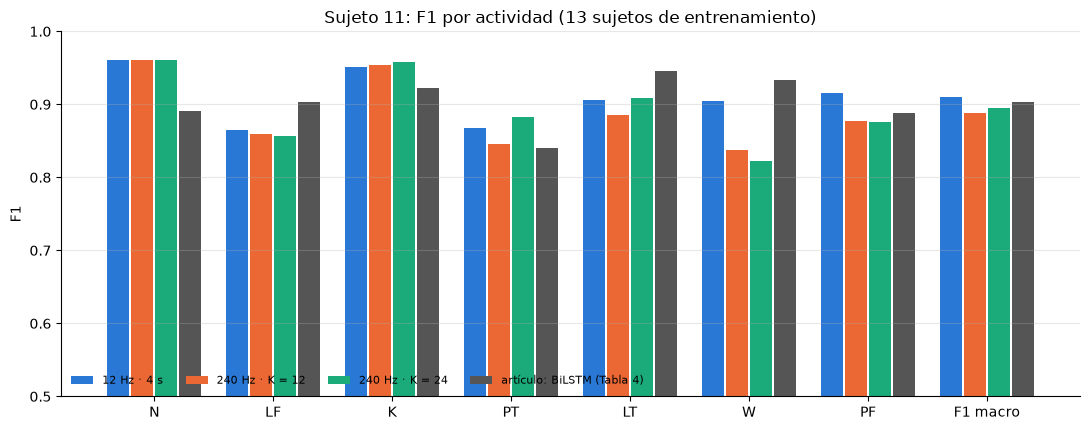

In [25]:
load_dir = lambda d: {r["held_out"]: r for r in (json.loads(p.read_text()) for p in sorted(d.glob("ronda_*.json")))}
r240 = {k: load_dir(fs240_dir(k)) for k in (12, 24)}
r240 = {k: v for k, v in r240.items() if v}
assert r240, "Todavía no hay rondas a 240 Hz."
SCALES = {"12 Hz · 4 s": f1_14} | {f"240 Hz · K = {k}": pd.DataFrame({v: {s: r["metricas"][v]["f1_macro"] for s, r in runs_k.items()}
                                                                 for v in L14_VARIANTS}) for k, runs_k in r240.items()}
subjects_240 = sorted(set().union(*[set(v) for v in r240.values()]))
for v in (V13_LR, V13_FT):
    tab = pd.DataFrame({name: f.reindex(subjects_240)[v] for name, f in SCALES.items()})
    tab.index.name = "sujeto"
    print(f"F1 macro · {v}:")
    display(pd.concat([tab, tab.agg(["mean", "std", "min"]).rename(index={"mean": "media", "std": "desv.", "min": "peor"})])
            .style.format("{:.3f}", na_rep="—").highlight_max(axis=1, color="#d8e8f8"))

rows = []
for k, f in ((k, SCALES[f"240 Hz · K = {k}"]) for k in r240):
    if len(f) < 5:
        continue
    for v in L14_VARIANTS:
        rows.append({"comparación": f"K = {k} − 12 Hz", "variante": v, **paired(f[v], f1_14[v])})
    rows.append({"comparación": f"K = {k}: ajuste fino − regresión logística", "variante": "13 sujetos",
                 **paired(f[V13_FT], f[V13_LR])})
if all(k in r240 and len(r240[k]) >= 5 for k in (12, 24)):
    for v in L14_VARIANTS:
        rows.append({"comparación": "K = 24 − K = 12", "variante": v,
                     **paired(SCALES["240 Hz · K = 24"][v], SCALES["240 Hz · K = 12"][v])})
if rows:
    display(pd.DataFrame(rows).set_index(["comparación", "variante"]).style.format(
        {"diferencia media": "{:+.3f}", "IC 95 % inf.": "{:+.3f}", "IC 95 % sup.": "{:+.3f}", "p (Wilcoxon)": "{:.4f}"}, na_rep="—"))

info_240 = pd.concat({f"K = {k}": pd.DataFrame([{"sujeto": s, "época CPC": r["info"]["cpc_12"]["best_epoch"], "C": r["info"][V12_LR]["C"],
                                                 "época ajuste fino": r["info"][V12_FT]["best_epoch"], "min ronda": r["minutos"]}
                                                for s, r in runs_k.items()]).set_index("sujeto") for k, runs_k in r240.items()})
print("Valores elegidos en la etapa de selección a 240 Hz:")
display(info_240.T.round(2))

if any(S11 in runs_k for runs_k in r240.values()):
    per_act = {}
    for name, (y, p) in {"12 Hz · 4 s": (l14[S11]["y"], l14[S11]["pred"][V13_FT]),
                         **{f"240 Hz · K = {k}": (runs_k[S11]["y"], runs_k[S11]["pred"][V13_FT])
                            for k, runs_k in r240.items() if S11 in runs_k}}.items():
        y, p = np.asarray(y), np.asarray(p)
        per_act[name] = [*f1_score(y, p, average=None, labels=range(len(LABELS))), f1_score(y, p, average="macro")]
    per_act["artículo: BiLSTM (Tabla 4)"] = [*(PAPER_TABLE4[l] for l in LABELS), PAPER_S11_F1]
    per_act = pd.DataFrame(per_act, index=[*LABELS, "F1 macro"])
    print("Sujeto 11, 13 sujetos de entrenamiento, ajuste fino lineal — F1 por actividad:")
    display(per_act.style.format("{:.3f}").highlight_max(axis=1, color="#d8e8f8"))

    fig, ax = plt.subplots(figsize=(11, 4.4))
    x, cols = np.arange(len(per_act)), list(per_act.columns)
    colors = ["#2a78d6", "#eb6834", "#1baa7a", "#555555"][-len(cols):] if len(cols) < 4 else ["#2a78d6", "#eb6834", "#1baa7a", "#555555"]
    w = 0.8 / len(cols)
    for j, (col, color) in enumerate(zip(cols, colors)):
        ax.bar(x + (j - (len(cols) - 1) / 2) * w, per_act[col], width=w * 0.92, color=color, label=col)
    ax.set_xticks(x, per_act.index)
    ax.set(ylim=(0.5, 1.0), ylabel="F1", title="Sujeto 11: F1 por actividad (13 sujetos de entrenamiento)")
    ax.grid(axis="y", alpha=0.3); ax.legend(frameon=False, fontsize=8, loc="lower left", ncol=len(cols))
    plt.tight_layout()
    plt.show()


## 11.4 Conclusiones de la sección (corrida del 12 de noviembre de 2026)

**F1 macro medio, LOSO con los 14 sujetos, 13 sujetos de entrenamiento:**

| Escala | Regresión logística | Ajuste fino · lineal | Desv. (ajuste fino) | Peor sujeto (ajuste fino) |
|---|---|---|---|---|
| **12 Hz · ventanas de 4 s (sección 10)** | **0.873** | **0.883** | 0.033 | 0.797 |
| 240 Hz · ventanas de 1 s · K = 12 (0.5 s) | 0.833 | 0.854 | 0.060 | 0.738 |
| 240 Hz · ventanas de 1 s · K = 24 (1 s) | 0.864 | 0.874 | 0.026 | 0.805 |

**1. La escala temporal del artículo no mejora el modelo.**
- **K = 12:** pierde con claridad. Ajuste fino lineal: −0.029 [−0.055, −0.009] frente a 12 Hz; gana en 4 de 14 sujetos (p = 0.009). La regresión logística pierde en los 14 (−0.039).
- **K = 24:** queda cerca, pero no por encima. Ajuste fino lineal: −0.009 [−0.019, +0.002]; gana en 5 de 14 (p = 0.15), así que la pérdida no está establecida. La regresión logística sí pierde: −0.009 [−0.016, −0.002] (p = 0.02).
- La comparación mezcla dos cambios: la frecuencia (240 frente a 12 Hz) y la ventana (1 s frente a 4 s). Con estas corridas no se pueden separar. Lo más probable es que la ventana más corta, con menos contexto, pese más que el detalle adicional de la señal.

**2. K = 24 es mejor que K = 12 a 240 Hz.**
- Regresión logística: +0.030 [+0.019, +0.045]; gana en los 14 sujetos (p = 0.0001). Predecir 1 s hacia adelante da una representación congelada claramente mejor que predecir 0.5 s.
- Ajuste fino lineal: +0.020 [−0.002, +0.047]; gana en 9 de 14 (p = 0.22). La media sube sobre todo por los sujetos 6 y 10, donde K = 12 falló (0.747 y 0.738) y K = 24 no (0.866 y 0.869).
- K = 24 tiene la menor dispersión entre personas de todo el notebook (0.026) y el mejor peor caso (0.805).
- Con K = 12, el ajuste fino no ayudó en los sujetos 2 y 6 (la validación eligió la época 0). En el sujeto 10 empeoró al reentrenar con 13 sujetos: 0.738 frente a 0.759 de la regresión logística.

**3. Sujeto 11 frente al artículo (13 sujetos de entrenamiento, ajuste fino lineal):**

| | 12 Hz · 4 s | 240 Hz · K = 12 | 240 Hz · K = 24 | Artículo (BiLSTM) |
|---|---|---|---|---|
| F1 macro | **0.910** | 0.888 | 0.895 | 0.903 |

- A 240 Hz, el sujeto 11 queda 0.008 (K = 24) y 0.015 (K = 12) por debajo del artículo, y por debajo de lo que ya daba a 12 Hz.
- Por actividad, la caída está en `W` (0.822 con K = 24, frente a 0.904 a 12 Hz y 0.934 en el artículo) y en `PF`. `PT` sí mejora con K = 24 (0.882, frente a 0.868 a 12 Hz y 0.840 en el artículo), y `N` y `K` siguen por encima del artículo.
- La aceleración de la mano a 240 Hz no conserva mejor `W`, que era la actividad en la que se esperaba ganar.

**4. Costo:** una ronda tarda en promedio ~8.6 min con K = 12 y ~14 min con K = 24. La corrida completa a 240 Hz tomó 5.1 h.

**Conclusión:** con el mismo modelo, las mismas 10 variables y los mismos 13 sujetos, **la escala del artículo (240 Hz, ventanas de 1 s) no mejora a la de 12 Hz con ventanas de 4 s**. Su mejor versión (K = 24) empata en la práctica con ajuste fino (−0.009, no establecido), pero no lo supera. **Se mantiene la configuración de 12 Hz y 4 s**, que también es mucho más barata. Los tres valores del sujeto 11 (0.888–0.910) están dentro de ±0.015 del 0.903 del artículo: el modelo está en el nivel del artículo con cualquiera de las dos escalas.


# 12. Representaciones `c_T` con t-SNE: los cuatro modelos en el sujeto 11

Cada ventana entra al modelo y sale como un vector `c_T` de 256 números (el último estado del GRU). La **t-SNE** convierte cada vector en un punto de un plano. Lo hace de modo que las ventanas parecidas en las 256 dimensiones queden cerca en el dibujo. Si se colorea cada punto con su actividad, se ve qué actividades separa el modelo y cuáles mezcla.

Los cuatro modelos se evalúan en el **sujeto 11**, el que se compara con el artículo. Ninguno lo vio durante el entrenamiento. **No se entrena nada**: se cargan los modelos guardados de cada ronda.

| Columna | Modelo | Sección |
|---|---|---|
| 1 | 12 Hz · ventanas de 4 s · 10 sujetos de entrenamiento (rondas principales) | 6 |
| 2 | 12 Hz · ventanas de 4 s · 13 sujetos de entrenamiento, como el artículo | 10 |
| 3 | 240 Hz · ventanas de 1 s · K = 12 · 13 sujetos | 11 |
| 4 | 240 Hz · ventanas de 1 s · K = 24 · 13 sujetos | 11 |

**Dos filas:**
- **CPC congelado:** `c_T` del preentrenamiento, que no usa etiquetas. Es lo que recibe la regresión logística.
- **Después del ajuste fino:** `c_T` de la red ajustada con etiquetas, de la que sale el F1 final.

**Cómo comparar los paneles:**
- **Sí se puede comparar** qué tan compacto y separado está cada grupo de color, y qué actividades se mezclan.
- **No se puede comparar** la posición, la orientación ni la distancia entre grupos de un panel a otro. Cada t-SNE se calcula por separado y sus ejes no significan nada.
- Para que los paneles sean comparables, todos usan las **mismas cantidades de ventanas por actividad** (como máximo 300), la misma *perplexity* y la misma semilla. A 12 Hz cada punto es una ventana de 4 s; a 240 Hz, de 1 s.
- **Medidas numéricas:** la tabla de abajo mide la separación en las **256 dimensiones originales**, no en el dibujo, así que sí es comparable entre modelos:
  - **silhouette** (de −1 a 1): qué tan cerca está cada ventana de las de su actividad frente a las de la actividad más cercana. Más alto es mejor; un valor cercano a 0 indica grupos traslapados.
  - **vecinos de la misma actividad:** de las 10 ventanas más cercanas a cada una, la fracción que tiene su misma actividad.

Antes de graficar, la celda comprueba que los modelos cargados reproducen las predicciones guardadas de cada ronda.

**Nota sobre el CPC congelado de 13 sujetos.** En las secciones 10 y 11, la clave `cpc_13` de cada `ronda_sXX.pt` se guardó **después** del ajuste fino: la red ajustada comparte el codificador y el GRU con el CPC, así que lo guardado es el CPC ya ajustado. Las predicciones y los F1 reportados no cambian, porque se calcularon durante la corrida. Para esta sección, el CPC congelado de 13 sujetos del sujeto 11 se vuelve a preentrenar con las mismas épocas y la misma semilla, y se guarda en `ronda_s11_cpc13_congelado.pt`. El acuerdo con la regresión logística guardada indica qué tan fiel es la reproducción.


,ventanas del sujeto 11,acuerdo con la regresión logística guardada,acuerdo con el ajuste fino guardado
12 Hz · 4 s · 10 sujetos,"5,868",100.0%,100.0%
12 Hz · 4 s · 13 sujetos,"5,868",100.0%,100.0%
240 Hz · 1 s · K = 12,"2,986",100.0%,100.0%
240 Hz · 1 s · K = 24,"2,986",100.0%,100.0%


Ventanas por actividad en cada panel: {'N': 300, 'LF': 283, 'K': 300, 'PT': 300, 'LT': 193, 'W': 131, 'PF': 193}


Separación de las actividades en c_T (sujeto 11; las medidas se calculan en las 256 dimensiones, no en el dibujo):


,F1 regresión logística,F1 ajuste fino,silhouette · CPC congelado,vecinos · CPC congelado,silhouette · después del ajuste fino,vecinos · después del ajuste fino
modelo,,,,,,
12 Hz · 4 s · 10 sujetos,0.908,0.908,0.165,0.848,0.203,0.878
12 Hz · 4 s · 13 sujetos,0.909,0.910,0.172,0.871,0.219,0.899
240 Hz · 1 s · K = 12,0.888,0.888,0.101,0.794,0.101,0.794
240 Hz · 1 s · K = 24,0.894,0.895,0.129,0.835,0.160,0.862


Fracción de los 10 vecinos más cercanos con la misma actividad, por actividad:


,,N,LF,K,PT,LT,W,PF
CPC congelado,12 Hz · 4 s · 10 sujetos,0.82,0.84,0.96,0.80,0.73,0.89,0.90
después del ajuste fino,12 Hz · 4 s · 10 sujetos,0.85,0.86,0.96,0.85,0.81,0.88,0.93
CPC congelado,12 Hz · 4 s · 13 sujetos,0.89,0.83,0.95,0.86,0.76,0.86,0.92
después del ajuste fino,12 Hz · 4 s · 13 sujetos,0.91,0.87,0.95,0.89,0.84,0.87,0.94
CPC congelado,240 Hz · 1 s · K = 12,0.82,0.76,0.95,0.71,0.70,0.80,0.76
después del ajuste fino,240 Hz · 1 s · K = 12,0.82,0.76,0.95,0.71,0.70,0.80,0.76
CPC congelado,240 Hz · 1 s · K = 24,0.86,0.81,0.96,0.77,0.74,0.85,0.83
después del ajuste fino,240 Hz · 1 s · K = 24,0.88,0.83,0.96,0.82,0.80,0.84,0.86


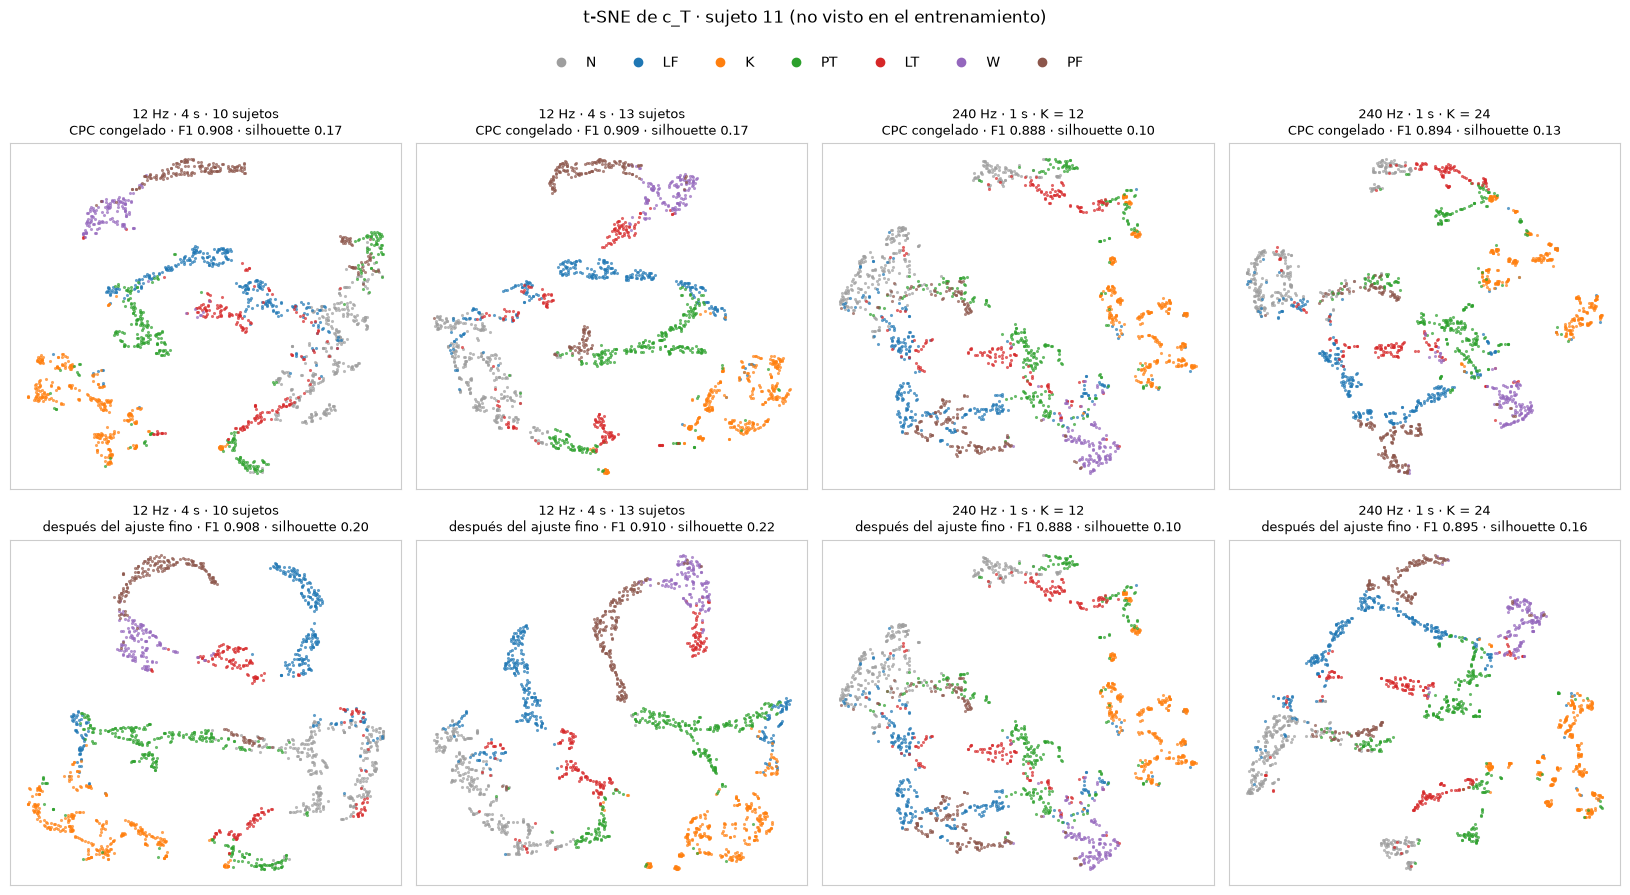

Sección 12: 10.5 min


In [26]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_samples
from sklearn.neighbors import NearestNeighbors

TSNE_SUBJECT, TSNE_MAX_PER_CLASS, TSNE_PERPLEXITY, KNN_K = 11, 300, 30, 10
REP_FROZEN, REP_FT = "CPC congelado", "después del ajuste fino"
# nombre: (carpeta de la ronda, clave del CPC, clave del ajuste fino, K a 240 Hz o None a 12 Hz, variante LR, variante FT)
TSNE_MODELS = {
    "12 Hz · 4 s · 10 sujetos": (RUN_DIR / "articulo_10", "cpc", V_FTL, None, V_LR, V_FTL),
    "12 Hz · 4 s · 13 sujetos": (L14_DIR, "cpc_13", V13_FT, None, V13_LR, V13_FT),
    "240 Hz · 1 s · K = 12": (fs240_dir(12), "cpc_13", V13_FT, 12, V13_LR, V13_FT),
    "240 Hz · 1 s · K = 24": (fs240_dir(24), "cpc_13", V13_FT, 24, V13_LR, V13_FT),
}


def ct_of_round(folder, cpc_key, ft_key, k, v_lr, v_ft):
    """c_T del sujeto de prueba con el CPC congelado y con la red ajustada, cargados de la ronda guardada."""
    global S_T
    path = folder / f"ronda_s{TSNE_SUBJECT:02d}.json"
    res = json.loads(path.read_text())
    states = torch.load(path.with_suffix(".pt"), map_location=DEVICE)
    spec, frame = (SPEC_240, sup_240) if k else (INPUT_SETS["articulo_10"], sup_index)
    held = frame.loc[res["index"]]
    y = held["target"].to_numpy()
    assert np.array_equal(y, np.asarray(res["y"]))
    scaler = res.get("scaler") or fit_scaler(spec, res.get("train13", res.get("train_subjects")))
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, spec).T)).to(DEVICE)
    starts = starts_of(held)
    build = (lambda: build_cpc_240(10, k)) if k else (lambda: build_cpc(10))
    cpc = build()
    if cpc_key == "cpc":
        cpc.load_state_dict(states["cpc"])
    else:
        # En las secciones 10 y 11, "cpc_13" se guardó después del ajuste fino (comparte el codificador con la red ajustada),
        # así que el CPC congelado de 13 sujetos se vuelve a preentrenar con las mismas épocas y semilla, y se guarda aparte.
        frozen_path = path.with_name(path.stem + "_cpc13_congelado.pt")
        if not frozen_path.exists():
            epochs = res["info"]["cpc_12"]["best_epoch"]
            if k:
                rnd = prepare_round_240(TSNE_SUBJECT, tuple(res["train13"]))
                cpc, _ = train_cpc_240(rnd, k, SEED, epochs=epochs)
            else:
                rnd = prepare_round_14(TSNE_SUBJECT, tuple(res["train13"]))
                cpc, _ = train_cpc_fixed(rnd, epochs, SEED)
            torch.save(cpc.state_dict(), frozen_path)
            S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler, spec).T)).to(DEVICE)
        cpc.load_state_dict(torch.load(frozen_path, map_location=DEVICE))
    cpc.eval()
    ft = CPCClassifier(build(), "lineal").to(DEVICE); ft.load_state_dict(states[ft_key]); ft.eval()
    frozen = cpc_features(cpc, starts).float().cpu().numpy()
    tuned = batched(ft.features, starts).float().cpu().numpy()
    # Comprobación: los modelos cargados repiten las predicciones guardadas de la ronda
    acuerdo_lr = float((joblib.load(path.with_suffix(".joblib")).predict(frozen) == np.asarray(res["pred"][v_lr])).mean())
    acuerdo_ft = float((predict(ft, starts) == np.asarray(res["pred"][v_ft])).mean())
    del cpc, ft, states
    return {"y": y, REP_FROZEN: frozen, REP_FT: tuned, "f1_lr": res["metricas"][v_lr]["f1_macro"],
            "f1_ft": res["metricas"][v_ft]["f1_macro"], "acuerdo_lr": acuerdo_lr, "acuerdo_ft": acuerdo_ft}


paths_ok = [(f / f"ronda_s{TSNE_SUBJECT:02d}.pt").exists() for f, *_ in TSNE_MODELS.values()]
if not all(paths_ok):
    print("Faltan rondas guardadas del sujeto 11; esta sección se omite:",
          [n for n, ok in zip(TSNE_MODELS, paths_ok) if not ok])
else:
    t0, saved_S_T = time.time(), S_T
    reps = {}
    for name, (folder, cpc_key, ft_key, k, v_lr, v_ft) in TSNE_MODELS.items():
        if k:
            with datos_240():
                reps[name] = ct_of_round(folder, cpc_key, ft_key, k, v_lr, v_ft)
        else:
            reps[name] = ct_of_round(folder, cpc_key, ft_key, k, v_lr, v_ft)
    S_T = saved_S_T
    check = pd.DataFrame({n: {"ventanas del sujeto 11": len(r["y"]), "acuerdo con la regresión logística guardada": r["acuerdo_lr"],
                              "acuerdo con el ajuste fino guardado": r["acuerdo_ft"]} for n, r in reps.items()}).T
    display(check.style.format({"ventanas del sujeto 11": "{:,.0f}", "acuerdo con la regresión logística guardada": "{:.1%}",
                                "acuerdo con el ajuste fino guardado": "{:.1%}"}))
    assert (check["acuerdo con el ajuste fino guardado"] > 0.99).all(), "Una red ajustada no reproduce las predicciones guardadas"
    if (check["acuerdo con la regresión logística guardada"] < 0.97).any():
        print("Aviso: un CPC congelado reentrenado difiere del original (el entrenamiento en MPS no es del todo determinista)")

    # Mismo número de ventanas por actividad en los cuatro modelos (como máximo TSNE_MAX_PER_CLASS)
    n_per_class = {c: min(TSNE_MAX_PER_CLASS, *[(r["y"] == c).sum() for r in reps.values()]) for c in range(len(LABELS))}
    rng = np.random.default_rng(SEED)
    for r in reps.values():
        r["muestra"] = np.sort(np.concatenate([rng.choice(np.flatnonzero(r["y"] == c), n, replace=False)
                                               for c, n in n_per_class.items() if n > 0]))
    print("Ventanas por actividad en cada panel:", {LABELS[c]: int(n) for c, n in n_per_class.items()})

    # Medidas de separación en las 256 dimensiones (estandarizadas) y t-SNE a 2 dimensiones
    rows, per_act, emb = [], {}, {}
    for name, r in reps.items():
        y = r["y"][r["muestra"]]
        row = {"modelo": name, "F1 regresión logística": r["f1_lr"], "F1 ajuste fino": r["f1_ft"]}
        for rep in (REP_FROZEN, REP_FT):
            X = StandardScaler().fit_transform(r[rep][r["muestra"]])
            sil = silhouette_samples(X, y)
            nn_idx = NearestNeighbors(n_neighbors=KNN_K + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
            same = (y[nn_idx] == y[:, None]).mean(1)
            row[f"silhouette · {rep}"], row[f"vecinos · {rep}"] = sil.mean(), same.mean()
            per_act[(rep, name)] = pd.Series(same, index=y).groupby(level=0).mean().rename(index=dict(enumerate(LABELS)))
            emb[(rep, name)] = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, init="pca", learning_rate="auto",
                                    random_state=SEED).fit_transform(X)
        rows.append(row)
    sep = pd.DataFrame(rows).set_index("modelo")
    print("Separación de las actividades en c_T (sujeto 11; las medidas se calculan en las 256 dimensiones, no en el dibujo):")
    display(sep.style.format("{:.3f}").highlight_max(axis=0, color="#d8e8f8"))
    print(f"Fracción de los {KNN_K} vecinos más cercanos con la misma actividad, por actividad:")
    display(pd.DataFrame(per_act).T[LABELS].style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0.3, vmax=1.0))

    fig, axes = plt.subplots(2, len(reps), figsize=(4.1 * len(reps), 8.4))
    for j, (name, r) in enumerate(reps.items()):
        y = r["y"][r["muestra"]]
        for i, rep in enumerate((REP_FROZEN, REP_FT)):
            ax, xy = axes[i, j], emb[(rep, name)]
            for c, lab in enumerate(LABELS):
                m = y == c
                ax.scatter(xy[m, 0], xy[m, 1], s=5, alpha=0.7, color=LABEL_COLORS[lab], linewidths=0, label=lab)
            f1 = r["f1_lr"] if rep == REP_FROZEN else r["f1_ft"]
            ax.set_title(f"{name}\n{rep} · F1 {f1:.3f} · silhouette {sep.loc[name, f'silhouette · {rep}']:.2f}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(True); s.set_color("#cccccc")
    handles = [plt.Line2D([], [], marker="o", ls="", color=LABEL_COLORS[l], markersize=6, label=l) for l in LABELS]
    fig.legend(handles=handles, loc="upper center", ncol=len(LABELS), frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle("t-SNE de c_T · sujeto 11 (no visto en el entrenamiento)", y=1.06)
    plt.tight_layout()
    plt.show()
    print(f"Sección 12: {(time.time() - t0) / 60:.1f} min")


## 12.1 Qué muestran los t-SNE (sujeto 11)

| Modelo | F1 ajuste fino | Silhouette (congelado → ajuste fino) | Vecinos de la misma actividad (congelado → ajuste fino) |
|---|---|---|---|
| 12 Hz · 4 s · 10 sujetos | 0.908 | 0.165 → 0.203 | 0.848 → 0.878 |
| **12 Hz · 4 s · 13 sujetos** | **0.910** | **0.172 → 0.219** | **0.871 → 0.899** |
| 240 Hz · 1 s · K = 12 | 0.888 | 0.101 → 0.101 | 0.794 → 0.794 |
| 240 Hz · 1 s · K = 24 | 0.895 | 0.129 → 0.160 | 0.835 → 0.862 |

1. **Las medidas siguen el mismo orden que el F1.** 12 Hz con 13 sujetos separa mejor las actividades; luego vienen 12 Hz con 10, 240 Hz con K = 24 y, al final, 240 Hz con K = 12. La t-SNE confirma, desde la representación, lo que ya decían las secciones 10 y 11.
2. **A 12 Hz los grupos son trayectorias largas y limpias; a 240 Hz, más fragmentadas.** Con ventanas de 4 s, ventanas consecutivas comparten 3.5 s de señal, así que `c_T` cambia poco a poco y dibuja "hilos" continuos. Con ventanas de 1 s sin traslape, cada punto es más independiente y los grupos se parten en trozos.
3. **El ajuste fino compacta los grupos** (la silhouette sube de 0.17 a 0.22 a 12 Hz con 13 sujetos). Los cambios principales están en `LT` (0.76 → 0.84 de vecinos) y `PT` (0.86 → 0.89), las actividades de la mesa. Con 240 Hz y K = 12 ambas filas son idénticas: en esta ronda la validación interna eligió 0 épocas de ajuste fino.
4. **Ya con el CPC congelado, sin etiquetas, las actividades forman grupos.** `K` (0.95–0.96 de vecinos en todos los modelos), `PF` y `W` se separan casi por completo. Lo que aprendió el preentrenamiento contrastivo ya está organizado por actividad.
5. **Las actividades que se mezclan son `LT`, `PT` y `N`** en todos los modelos: los puntos rojos (`LT`) y verdes (`PT`) aparecen junto a los grises (`N`). Coincide con que `PT` y `LT` son las actividades con F1 más bajo (sección 13). A 240 Hz la mezcla es mayor (`PT` 0.71–0.82 y `LT` 0.70–0.80 de vecinos).
6. **Pasar de 10 a 13 sujetos casi no cambia el F1 del sujeto 11** (0.908 → 0.910), pero sí la representación: el CPC congelado de 13 sujetos agrupa mejor `N` (0.82 → 0.89 de vecinos) y `PT` (0.80 → 0.86). Esto coincide con la sección 10, donde la regresión logística seguía mejorando con más sujetos y el ajuste fino no.

Es un solo sujeto y una sola semilla, y la t-SNE es una ayuda visual: las conclusiones del notebook se basan en el F1 de los 14 sujetos.


# 13. Desempeño por actividad

Se juntan las predicciones de todos los sujetos evaluados (cada uno predicho por el modelo que no lo vio) y se calcula el F1 de cada actividad. Interesa sobre todo:

- si el MLP mejora las actividades difíciles del proyecto (`PT` y `LT`, las que ocurren a la altura de la mesa);
- en qué actividades pierden o ganan las 10 variables del artículo frente a las 30.

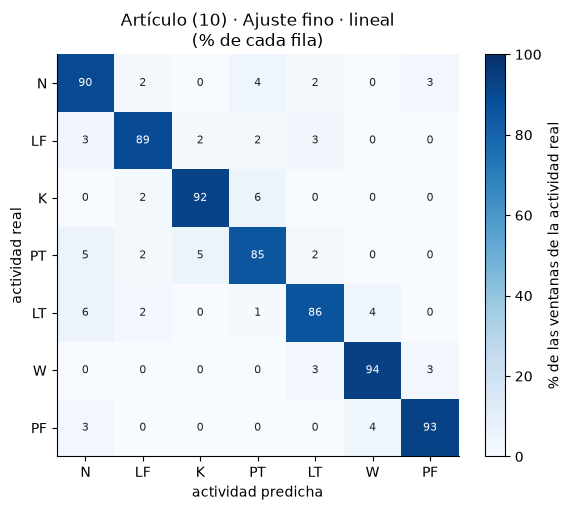

In [27]:
def pooled(set_key, v):
    rs = runs[set_key].values()
    return np.concatenate([r["y"] for r in rs]), np.concatenate([r["pred"][v] for r in rs])


per_activity = pd.DataFrame({(SET_NAMES[s], v): dict(zip(LABELS, f1_score(*pooled(s, v), average=None, labels=range(len(LABELS)))))
                             for s in runs for v in VARIANTS}).T
per_activity["F1 macro (juntas)"] = per_activity[LABELS].mean(axis=1)
display(per_activity.style.format("{:.3f}").background_gradient(cmap="Blues", subset=LABELS, vmin=0.5, vmax=1.0))

best_set, best_v = max(((s, v) for s in runs for v in VARIANTS), key=lambda sv: by_subject[(SET_NAMES[sv[0]], sv[1])].mean())
y, pred = pooled(best_set, best_v)
cm = confusion_matrix(y, pred, labels=range(len(LABELS)), normalize="true") * 100
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 60 else "#222222")
ax.set_xticks(range(len(LABELS)), LABELS); ax.set_yticks(range(len(LABELS)), LABELS)
ax.set(xlabel="actividad predicha", ylabel="actividad real", title=f"{SET_NAMES[best_set]} · {best_v}\n(% de cada fila)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="% de las ventanas de la actividad real")
plt.tight_layout()
plt.show()

# 14. Hiperparámetros elegidos y costo

Por ronda: la `C` de la regresión logística, la configuración del MLP elegida en la validación interna, las épocas elegidas por la parada temprana y los minutos de cada etapa. Si la regresión logística no convergió en alguna ronda, la columna `convergió` lo indica. `acuerdo PyTorch` es la fracción de ventanas en que la capa lineal copiada de la regresión logística predice lo mismo que ella (debe ser ≈ 1).

In [28]:
cost = pd.DataFrame([{"conjunto": SET_NAMES[s], "sujeto": subj, "época CPC": r["info"]["cpc"]["best_epoch"],
                      "min CPC": r["info"]["cpc"]["minutes"], "C logística": r["info"][V_LR]["C"],
                      "convergió": r["info"][V_LR]["converged"], "acuerdo PyTorch": r["info"][V_LR]["acuerdo_pytorch"],
                      "MLP lr": r["info"][V_MLP0]["lr"], "MLP dropout": r["info"][V_MLP0]["dropout"],
                      "época MLP congelado": r["info"][V_MLP0]["best_epoch"],
                      "época FT lineal": r["info"][V_FTL]["best_epoch"], "época FT MLP": r["info"][V_FTM]["best_epoch"],
                      "min FT lineal": r["info"][V_FTL]["minutes"], "min FT MLP": r["info"][V_FTM]["minutes"],
                      "min ronda": r["minutos"]} for s, rs in runs.items() for subj, r in rs.items()])
display(cost.groupby("conjunto").agg({"época CPC": "mean", "min CPC": "mean", "C logística": lambda c: c.mode().iloc[0],
                                     "convergió": "mean", "acuerdo PyTorch": "min",
                                     "MLP lr": lambda c: c.mode().iloc[0], "MLP dropout": lambda c: c.mode().iloc[0],
                                     "época MLP congelado": "mean", "época FT lineal": "mean",
                                     "época FT MLP": "mean", "min FT lineal": "mean", "min FT MLP": "mean",
                                     "min ronda": "mean"}).round(2))

,época CPC,min CPC,C logística,convergió,acuerdo PyTorch,MLP lr,MLP dropout,época MLP congelado,época FT lineal,época FT MLP,min FT lineal,min FT MLP,min ronda
conjunto,,,,,,,,,,,,,
Artículo (10),12.83,2.49,0.3,1.0,1.0,0.0,0.2,15.5,9.0,6.75,2.95,2.76,9.13


# 15. Cómo leer los resultados

- **¿Bastan las 10 variables del artículo?** Familia *Variables* de la sección 8. Si el intervalo de la diferencia incluye el 0, las 10 variables (con sólo 2 sEMG y 8 de movimiento) rinden como las 30. Eso simplifica el sistema: menos variables y, sobre todo, menos sensores.
- **¿Conviene el MLP?** Familia *Cabezal*:
  - con el **CPC congelado**, una ventaja del MLP dice que `c_T` contiene la información, pero no de forma linealmente separable. El clasificador lineal sigue siendo la medida estándar de la calidad de la representación;
  - con **ajuste fino**, si no hay diferencia establecida, conviene el cabezal lineal: es más simple, tiene menos parámetros y es el del artículo.
- **Control:** si la regresión logística y la capa lineal de PyTorch dan F1 parecidos, la comparación con el MLP no depende de cómo se entrena el cabezal. Si la de PyTorch queda claramente por debajo, una ventaja de la regresión logística sobre el MLP congelado puede deberse en parte a la optimización.
- **¿Escala del artículo?** Sección 11. Si "K − 12 Hz" incluye el 0, la frecuencia de 240 Hz con ventanas de 1 s rinde como 12 Hz con 4 s, y conviene la escala más barata.
- **¿Más sujetos?** Sección 9. Si la diferencia "8 − 10 sujetos" es claramente negativa, la curva todavía sube y entrenar con más personas (como los 13 del artículo) probablemente ayudaría. La sección 10 lo comprueba con 12 y 13: si "13 − 12" y "13 − 10" incluyen el 0, la curva ya se aplanó.
- **Siguientes pasos si las 10 variables funcionan:**
  1. ~~probar la escala temporal del artículo~~: hecho en la sección 11 (240 Hz con ventanas de 1 s no mejora a 12 Hz con 4 s);
  2. medir cuánto aporta la sEMG dentro de las 10 variables (las 8 de movimiento solas);
  3. comparar `BALANCEO = "submuestreo"` con los pesos por clase;
  4. agregar semillas. La prueba con los sujetos 13 y 14 ya se abrió en la sección 10.

# 16. Conclusiones (corridas del 9 al 12 de noviembre de 2026)

Cinco corridas (más la t-SNE de la sección 12, que no entrena modelos nuevos), todas con la semilla 0. Las tres primeras son LOSO sobre los sujetos 1–12, sin usar los sujetos 13 y 14:

1. **Rondas principales:** 10 variables del artículo, pesos por clase (secciones 6–8).
2. **Curva de aprendizaje:** las mismas rondas con 4, 6 y 8 sujetos de entrenamiento (sección 9).
3. **Submuestreo de `N`:** las rondas principales con `BALANCEO = "submuestreo"`. Su notebook ejecutado está en `checkpoints/nb12_gru_variables_articulo_fs12_submuestreo/12_submuestreo_ejecutado.ipynb`.
4. **LOSO con 14 sujetos:** cada sujeto de 1–14 evaluado con 12 y con 13 sujetos de entrenamiento, como el artículo (sección 10). **Esta corrida usa los sujetos 13 y 14**, que hasta aquí estaban reservados.
5. **240 Hz con ventanas de 1 s:** el LOSO con 14 sujetos de la sección 10 con la escala temporal del artículo, con K = 12 y K = 24 (sección 11).

**F1 macro por sujeto evaluado (rondas principales):**

| Variante | Media | Desv. entre personas | Peor sujeto |
|---|---|---|---|
| CPC congelado · regresión logística | 0.860 | 0.034 | 0.790 |
| CPC congelado · MLP | 0.860 | 0.027 | 0.795 |
| **Ajuste fino · lineal** | **0.880** | 0.033 | 0.796 |
| Ajuste fino · MLP | 0.879 | 0.034 | 0.795 |
| *Control:* CPC congelado · lineal (PyTorch) | 0.848 | 0.034 | 0.769 |

## 1. Las 10 variables del artículo alcanzan a las 30 del proyecto

Con ajuste fino lineal, las 10 variables (2 sEMG + 8 MVNX) dan **0.880**; el CPC-GRU con 30 variables MVNX del notebook 10 dio **0.878**. La diferencia por sujeto es +0.002 [−0.009, +0.012]: las 10 variables ganan en 7 de 12 sujetos (p = 0.57). No hay diferencia: **con un tercio de las variables se obtiene el mismo desempeño**.

La comparación no es exacta (sección 8.1). La regresión logística sobre el CPC congelado sí sale bastante mejor que la sonda del notebook 10 (0.860 frente a 0.820), pero esa sonda usaba `C = 1` fija y otro escalado. Esa diferencia no debe atribuirse a las variables.

Por actividad (ajuste fino lineal, predicciones de los 12 sujetos juntas), las actividades a la altura de la mesa siguen siendo las difíciles: `PT` 0.838 y `LT` 0.849. En el notebook 10, con 30 variables, eran 0.827 y 0.813.

## 2. El MLP no mejora al clasificador lineal

| Comparación | Diferencia media [IC 95 %] | Gana el MLP | p |
|---|---|---|---|
| CPC congelado: MLP − regresión logística | −0.000 [−0.007, +0.007] | 6 de 12 | 0.97 |
| Ajuste fino: MLP − lineal | −0.001 [−0.009, +0.007] | 6 de 12 | 0.97 |

Las dos están empatadas, con o sin ajuste fino, y en ningún tamaño de la curva de aprendizaje el MLP le gana al lineal. Con el CPC congelado, esto dice que **`c_T` ya es linealmente separable**: las capas ocultas no encuentran información que un hiperplano no use.

Se recomienda el **cabezal lineal**: es el del artículo, tiene ~1 800 parámetros frente a ~100 000 y su versión congelada es una regresión logística convexa, sin hiperparámetros de optimización.

El control muestra que la capa lineal entrenada con descenso de gradiente queda un poco por debajo de la regresión logística (−0.011, gana en 1 de 12; p = 0.003). El MLP se entrena igual, así que podría tener una pequeña desventaja de optimización. Aun así, empata, y no hay indicios de que esté ocultando una ventaja real. Arrancar el ajuste fino lineal desde la regresión logística evitó esa pérdida: la copia predice exactamente lo mismo que la regresión logística en las 12 rondas.

## 3. El ajuste fino sí ayuda

- **Con el cabezal lineal:** +0.020 [+0.010, +0.032]; gana en 11 de 12 sujetos (p = 0.001).
- **Con el MLP:** +0.020 [+0.008, +0.031]; gana en 7 de 12 (p = 0.016). En 5 rondas, la validación interna se quedó con la época 0 y el ajuste fino no cambió el MLP.

## 4. Más sujetos ayudarían

| Sujetos de entrenamiento | 4 | 6 | 8 | 10 |
|---|---|---|---|---|
| Ajuste fino · lineal (media) | 0.826 | 0.852 | 0.868 | 0.880 |
| Ajuste fino · lineal (peor sujeto) | 0.697 | 0.779 | 0.806 | 0.796 |
| CPC congelado · regresión logística (media) | 0.807 | 0.840 | 0.846 | 0.860 |

- **La curva no se aplana:** pasar de 8 a 10 sujetos todavía mejora el ajuste fino lineal en +0.012 [+0.003, +0.022]. Con 8 sujetos el F1 es más bajo que con 10 en 9 de 12 personas (p = 0.034).
- **La ganancia por cada 2 personas se reduce:** +0.026, +0.016 y +0.012.
- **Con 4 sujetos se pierde 0.054**, y el F1 baja en los 12 sujetos evaluados. Los primeros sujetos son los que más importan, sobre todo para el peor caso.

La extrapolación de esta curva sugería ~+0.01 más con 12 o 13 sujetos. **La sección 10 no lo confirma** (punto 6).

## 5. El submuestreo de `N` no mejora

| Variante | Submuestreo − pesos [IC 95 %] | Gana el submuestreo | p |
|---|---|---|---|
| CPC congelado · regresión logística | +0.001 [−0.002, +0.004] | 7 de 12 | 0.73 |
| CPC congelado · MLP | +0.005 [−0.000, +0.010] | 10 de 12 | 0.11 |
| Ajuste fino · lineal | −0.008 [−0.016, −0.000] | 4 de 12 | 0.08 |
| Ajuste fino · MLP | −0.005 [−0.017, +0.005] | 5 de 12 | 0.52 |

Con la mejor variante (ajuste fino lineal), el submuestreo tiende a empeorar: menos ventanas de entrenamiento sin una ganancia en las clases pequeñas. **Se mantienen los pesos por clase.** Como el submuestreo no ayudó, aumentar las clases pequeñas con ruido (el otro paso de balanceo del artículo) queda con prioridad baja.

## 6. Con 12 y 13 sujetos la curva del ajuste fino ya está plana

LOSO con los 14 sujetos (sección 10):

| Variante | 12 sujetos | 13 sujetos | 13 − 12 [IC 95 %] | p |
|---|---|---|---|---|
| CPC congelado · regresión logística | 0.872 | 0.873 | +0.000 [−0.003, +0.004] | 0.90 |
| **Ajuste fino · lineal** | **0.885** | **0.883** | −0.002 [−0.008, +0.003] | 0.86 |

- Sobre los sujetos 1–12, el ajuste fino lineal da 0.880 con 10 sujetos, 0.882 con 12 y 0.879 con 13: **13 − 10 = −0.001 [−0.010, +0.008]** (p = 0.85). La ganancia por cada 2 personas bajó hasta cero.
- La regresión logística sobre el CPC congelado sí sigue subiendo: 13 − 10 = +0.011 (gana en 10 de 12; p = 0.016). El ajuste fino ya obtenía esa ganancia con 10 sujetos.
- **Conclusión:** con este modelo y este protocolo, entrenar con más personas ya no ayuda. Las mejoras tendrían que venir de la escala temporal, las variables o la arquitectura.

**Sujetos 13 y 14:** con 13 sujetos de entrenamiento y ajuste fino lineal dan 0.902 y 0.913, frente a 0.879 de media en los sujetos 1–12. El diseño se eligió sólo con 1–12, así que este es el resultado de la prueba final: el modelo generaliza a las dos personas reservadas.

**Sujeto 11 frente al artículo:** 0.910 aquí y 0.903 en el artículo (BiLSTM, 13 sujetos). Por actividad, aquí es mejor en `N`, `K`, `PT` y `PF`, y peor en `LF`, `LT` y `W`. Con una sola persona, una semilla y un protocolo distinto, eso dice que **se alcanza el nivel del artículo**, no que se lo supere. El sujeto 11 es de los fáciles (0.908 con 10 sujetos). La media de los 14 sujetos, **0.883**, es la mejor estimación del desempeño.

## 7. La escala temporal del artículo no mejora el modelo

LOSO con los 14 sujetos, 13 sujetos de entrenamiento (sección 11):

| Escala | Ajuste fino · lineal | Frente a 12 Hz [IC 95 %] | p | Sujeto 11 |
|---|---|---|---|---|
| **12 Hz · ventanas de 4 s** | **0.883** | — | — | **0.910** |
| 240 Hz · 1 s · K = 12 | 0.854 | −0.029 [−0.055, −0.009] | 0.009 | 0.888 |
| 240 Hz · 1 s · K = 24 | 0.874 | −0.009 [−0.019, +0.002] | 0.15 | 0.895 |

- Con K = 12 se pierde con claridad. Con K = 24 la pérdida es pequeña y no está establecida, pero tampoco hay ganancia.
- A 240 Hz conviene K = 24 (predecir 1 s): la regresión logística mejora +0.030 sobre K = 12 en los 14 sujetos.
- La comparación cambia a la vez la frecuencia y la longitud de la ventana. Lo más probable es que pese más la pérdida de contexto (1 s frente a 4 s).
- Con cualquiera de las escalas, el sujeto 11 queda dentro de ±0.015 del 0.903 del artículo.

## 8. La t-SNE de `c_T` confirma el orden de los modelos

En el sujeto 11 (sección 12), las medidas de separación en las 256 dimensiones siguen el mismo orden que el F1: 12 Hz con 13 sujetos (silhouette 0.22, 90 % de vecinos de la misma actividad), luego 12 Hz con 10, 240 Hz con K = 24 y 240 Hz con K = 12 (0.10, 79 %). Ya sin etiquetas, el CPC agrupa las actividades. El ajuste fino compacta sobre todo `LT` y `PT`, que siguen siendo las que se mezclan con `N`.

## Configuración recomendada y siguientes pasos

**Configuración recomendada:** CPC-GRU con las 10 variables del artículo, ajuste fino con cabezal lineal que arranca de la regresión logística, y pesos por clase. F1 macro **0.880 ± 0.033** en LOSO con 12 sujetos y **0.883 ± 0.033** en LOSO con los 14 (13 sujetos de entrenamiento). Para un modelo final basta con 10–13 sujetos de entrenamiento; agregar más personas del mismo protocolo no ayudaría. La escala del artículo (240 Hz, ventanas de 1 s) no mejora este resultado y cuesta mucho más (sección 11).

**Siguientes pasos:**

1. ~~**Escala temporal del artículo**~~: hecha en la sección 11; no mejora. Si se quisiera separar el efecto de la frecuencia del de la ventana, faltaría probar 240 Hz con ventanas de 4 s, o 12 Hz con ventanas de 1 s.
2. **Aporte de la sEMG:** las 8 variables de movimiento solas, frente a las 10.
3. **Semillas:** más semillas para confirmar las diferencias pequeñas (todas las de este notebook son de la semilla 0).
4. **Nueva prueba limpia:** los sujetos 13 y 14 ya se usaron en la sección 10. Cualquier cambio de diseño que se elija desde ahora debe evaluarse con LOSO sobre los 14, sin una prueba reservada, o con datos de personas nuevas.